# Spain / France / Portugal — terminal & trade tracker

Country-level exploration on DuckDB (`data/kpler_trades.duckdb`).

**Units:** monthly series in **kbd** = `(Volume bbl / 1000) / days_in_month`.
Lifetime totals stay in **mb** (kbd is a flow rate).

Default filter: `Trade status = Delivered`. Time axis = **origin month**.

**Crude toggle:** `INCLUDE_CRUDE` in the setup cell (default `False`). Applies to
product insights and Sankey flows — crude often warrants a separate cut.

Seasonality charts follow the demand-dashboard pattern: one panel per product,
calendar month on x, one line per year (current year highlighted).
Sankeys: origin/terminal → product → terminal/destination for a single month.

In [20]:
from __future__ import annotations

import calendar
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from matplotlib.lines import Line2D

ROOT = Path("..").resolve()
DB_PATH = ROOT / "data" / "kpler_trades.duckdb"
assert DB_PATH.exists(), f"Missing {DB_PATH}. Run: python bootstrap_duckdb.py"

COUNTRIES = ["Spain", "France", "Portugal"]
STATUS = "Delivered"
SEASONALITY_END = "2026-06"  # inclusive YYYY-MM of usable history
HIGHLIGHT_YEAR = 2026
PRIOR_YEAR = 2025

# Crude often dominates volumes — set False to study products-only flows.
INCLUDE_CRUDE = False

# Sankey controls
# mode: "month" = single month; "cumulative" = sum over [SANKEY_START, SANKEY_END]
SANKEY_MODE = "month"  # "month" | "cumulative"
SANKEY_MONTH = SEASONALITY_END  # used when mode == "month"
SANKEY_START = "2016-01"  # used when mode == "cumulative"
SANKEY_END = SEASONALITY_END
SANKEY_TOP_N = 10  # top nodes per side after aggregation
# Also draw one import Sankey per calendar year in the cumulative window
SANKEY_ANNUAL_SNAPSHOTS = True

# Panels for YoY seasonality (Kpler Product names)
SEASONALITY_PRODUCTS = [
    "Crude",
    "Diesel",
    "Gasoil",
    "Gasoline",
    "Jet",
    "FO",
    "Naphtha",
    "Bitumen/Asphalt",
    "Kerosene",
    "Blending Comps",
]

MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

con = duckdb.connect(str(DB_PATH), read_only=True)
print(con.execute("SELECT COUNT(*) AS rows FROM trades").fetchdf())
print(DB_PATH)


      rows
0  1607940
C:\Users\luiscarlos.gaitan\OneDrive - Jain Global\Coding\prod_nowcast\data\kpler_trades.duckdb


In [21]:
def q(sql: str, params: list | None = None) -> pd.DataFrame:
    return con.execute(sql, params or []).fetchdf()


VOL = 'TRY_CAST("Volume (bbl)" AS DOUBLE)'
MONTH = 'substr(CAST("Date (origin)" AS VARCHAR), 1, 7)'
CAL_MONTH = 'CAST(substr(CAST("Date (origin)" AS VARCHAR), 6, 2) AS INTEGER)'
YEAR = 'CAST(substr(CAST("Date (origin)" AS VARCHAR), 1, 4) AS INTEGER)'


def country_placeholders(n: int) -> str:
    return ", ".join(["?"] * n)


def days_in_yyyymm(month: str) -> int:
    y, m = int(month[:4]), int(month[5:7])
    return calendar.monthrange(y, m)[1]


def add_kbd(df: pd.DataFrame, kb_col: str = "volume_kb", month_col: str = "month") -> pd.DataFrame:
    """kb (thousand bbl in the month) -> kbd (thousand bbl per day)."""
    out = df.copy()
    out["days"] = out[month_col].map(days_in_yyyymm)
    out["volume_kbd"] = out[kb_col] / out["days"]
    return out


def month_index(s: pd.Series) -> pd.PeriodIndex:
    return pd.PeriodIndex(s.astype(str), freq="M")


def top_n_bucket(df: pd.DataFrame, key: str, value: str, n: int) -> pd.DataFrame:
    totals = df.groupby(key)[value].sum().sort_values(ascending=False)
    keep = set(totals.head(n).index)
    out = df.copy()
    out[key] = out[key].where(out[key].isin(keep), "Other")
    return out


def stacked_area_kbd(wide: pd.DataFrame, title: str):
    ax = wide.plot(kind="area", stacked=True, figsize=(11, 4), title=title)
    ax.set_ylabel("kbd")
    ax.set_xlabel("Origin month")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
    plt.tight_layout()
    plt.show()
    return ax


def crude_sql_filter(include_crude: bool | None = None, *, alias: str = "") -> str:
    """SQL AND-clause to drop crude/condensate when INCLUDE_CRUDE is False."""
    flag = INCLUDE_CRUDE if include_crude is None else include_crude
    if flag:
        return ""
    p = f'{alias}.' if alias else ""
    return f"""
      AND NOT (
        {p}Family = 'Dirty'
        OR {p}Product = 'Crude'
        OR {p}Product = 'Condensate'
        OR {p}\"Group\" = 'Crude/Co'
      )
    """


def crude_label(include_crude: bool | None = None) -> str:
    flag = INCLUDE_CRUDE if include_crude is None else include_crude
    return "incl. crude" if flag else "excl. crude"

## 0. Unit check (kbd)

`kbd = monthly kb / days_in_month`. Spot-check vs intuition:
- Spain crude imports ~1.0–1.5 mbd is consistent with refining intake.
- Portugal diesel+gasoil imports ~40–70 kbd is below inland demand (~80–120 kbd on the CORES-style charts) — expected if local refining covers part of the barrel.

In [22]:
def unit_check(country: str, products: list[str], start: str = "2024-01", end: str = "2024-12"):
    ph = country_placeholders(len(products))
    df = q(
        f"""
        SELECT {MONTH} AS month,
               ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          AND COALESCE(Product, '(blank)') IN ({ph})
          AND {MONTH} BETWEEN ? AND ?
        GROUP BY 1 ORDER BY 1
        """,
        [STATUS, country, *products, start, end],
    )
    return add_kbd(df)


checks = {
    "Spain Crude": unit_check("Spain", ["Crude"]),
    "Portugal Diesel+Gasoil": unit_check("Portugal", ["Diesel", "Gasoil"]),
    "France Crude": unit_check("France", ["Crude"]),
}
for label, df in checks.items():
    print(f"{label} 2024 — mean {df['volume_kbd'].mean():.1f} kbd | "
          f"sum {df['volume_kb'].sum()/1000:.1f} mb")
    display(df[["month", "volume_kb", "days", "volume_kbd"]].round(1))

Spain Crude 2024 — mean 1312.0 kbd | sum 480.7 mb


,month,volume_kb,days,volume_kbd
0,2024-01,48115.2,31,1552.1
1,2024-02,35610.7,29,1228.0
2,2024-03,41521.3,31,1339.4
3,2024-04,40074.0,30,1335.8
4,2024-05,43555.7,31,1405.0
5,2024-06,34306.7,30,1143.6
6,2024-07,40516.6,31,1307.0
7,2024-08,42464.4,31,1369.8
8,2024-09,35761.8,30,1192.1
9,2024-10,36819.8,31,1187.7


Portugal Diesel+Gasoil 2024 — mean 51.2 kbd | sum 18.7 mb


,month,volume_kb,days,volume_kbd
0,2024-01,1352.2,31,43.6
1,2024-02,1985.4,29,68.5
2,2024-03,1607.6,31,51.9
3,2024-04,1175.8,30,39.2
4,2024-05,1928.7,31,62.2
5,2024-06,1532.1,30,51.1
6,2024-07,1482.9,31,47.8
7,2024-08,1344.8,31,43.4
8,2024-09,1461.9,30,48.7
9,2024-10,1831.9,31,59.1


France Crude 2024 — mean 977.0 kbd | sum 357.7 mb


,month,volume_kb,days,volume_kbd
0,2024-01,28763.7,31,927.9
1,2024-02,29765.1,29,1026.4
2,2024-03,25194.8,31,812.7
3,2024-04,26983.3,30,899.4
4,2024-05,29953.0,31,966.2
5,2024-06,28102.7,30,936.8
6,2024-07,34642.8,31,1117.5
7,2024-08,31044.3,31,1001.4
8,2024-09,24104.1,30,803.5
9,2024-10,33695.2,31,1086.9


## 1. Market snapshot (Delivered, lifetime mb)

,country,direction,trades,volume_mb
0,France,export,16872,1094.77
1,France,import,27937,6047.87
2,Portugal,export,7808,549.53
3,Portugal,import,8966,1275.36
4,Spain,export,32576,2463.55
5,Spain,import,34925,7444.34


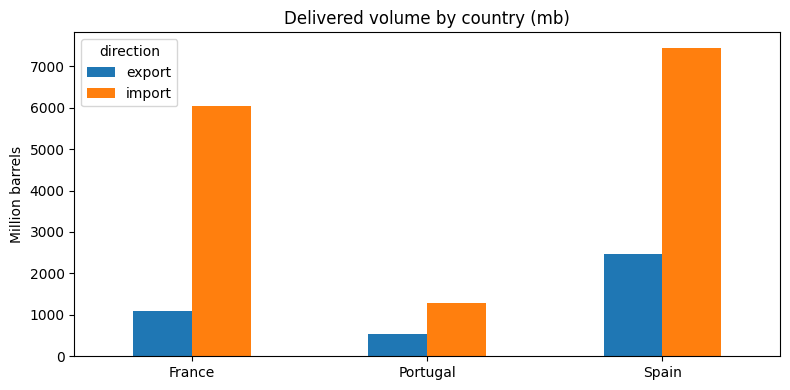

In [23]:
snap_sql = f"""
WITH base AS (
  SELECT
    "Country (destination)" AS country,
    'import' AS direction,
    {VOL} AS bbl
  FROM trades
  WHERE "Trade status" = ?
    AND "Country (destination)" IN ({country_placeholders(len(COUNTRIES))})
  UNION ALL
  SELECT
    "Country (origin)" AS country,
    'export' AS direction,
    {VOL} AS bbl
  FROM trades
  WHERE "Trade status" = ?
    AND "Country (origin)" IN ({country_placeholders(len(COUNTRIES))})
)
SELECT
  country,
  direction,
  COUNT(*) AS trades,
  ROUND(SUM(bbl) / 1e6, 2) AS volume_mb
FROM base
GROUP BY 1, 2
ORDER BY country, direction
"""
snapshot = q(snap_sql, [STATUS, *COUNTRIES, STATUS, *COUNTRIES])
display(snapshot)

pivot = snapshot.pivot(index="country", columns="direction", values="volume_mb").fillna(0)
ax = pivot.plot(kind="bar", figsize=(8, 4), title="Delivered volume by country (mb)")
ax.set_ylabel("Million barrels")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. Most important terminals (lifetime)

In [24]:
def top_import_terminals(country: str, n: int = 15) -> pd.DataFrame:
    return q(
        f"""
        SELECT
          "Installation Destination" AS installation,
          "Installation Destination Id" AS installation_id,
          COUNT(*) AS trades,
          ROUND(SUM({VOL}) / 1e6, 2) AS volume_mb,
          ROUND(100.0 * SUM({VOL}) / SUM(SUM({VOL})) OVER (), 1) AS pct_of_country
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          AND "Installation Destination" IS NOT NULL
          AND "Installation Destination" <> ''
        GROUP BY 1, 2
        ORDER BY SUM({VOL}) DESC
        LIMIT ?
        """,
        [STATUS, country, n],
    )


def top_export_terminals(country: str, n: int = 15) -> pd.DataFrame:
    return q(
        f"""
        SELECT
          "Installation origin" AS installation,
          "Installation origin id" AS installation_id,
          COUNT(*) AS trades,
          ROUND(SUM({VOL}) / 1e6, 2) AS volume_mb,
          ROUND(100.0 * SUM({VOL}) / SUM(SUM({VOL})) OVER (), 1) AS pct_of_country
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (origin)" = ?
          AND "Installation origin" IS NOT NULL
          AND "Installation origin" <> ''
        GROUP BY 1, 2
        ORDER BY SUM({VOL}) DESC
        LIMIT ?
        """,
        [STATUS, country, n],
    )


for c in COUNTRIES:
    print("=" * 60)
    print(c, "— TOP IMPORT TERMINALS")
    display(top_import_terminals(c))
    print(c, "— TOP EXPORT TERMINALS")
    display(top_export_terminals(c))

Spain — TOP IMPORT TERMINALS


,installation,installation_id,trades,volume_mb,pct_of_country
0,Repsol Cartagena Refinery,1243,2929,1243.84,17.1
1,Gibraltar-San Roque Refinery,1245,1911,953.76,13.1
2,Tarragona Refinery,1229,1994,773.13,10.6
3,Repsol Petronor Refinery,1249,1208,737.26,10.1
4,La Rabida,1247,1527,734.31,10.1
5,BP Castellon Refinery,1228,927,391.55,5.4
6,Repsol Coruna Refinery,1250,1013,279.66,3.8
7,Vopak Algeciras,1912,1666,242.31,3.3
8,Tenerife Refinery,1188,2048,194.04,2.7
9,Vopak Terquimsa Barcelona,1241,939,193.01,2.6


Spain — TOP EXPORT TERMINALS


,installation,installation_id,trades,volume_mb,pct_of_country
0,Repsol Cartagena Refinery,1243,4305,403.00,17.1
1,Gibraltar-San Roque Refinery,1245,5845,387.08,16.4
2,Bilbao Oil Facilities,1839,1921,255.75,10.9
3,Torre Arenillas,2049,2281,228.55,9.7
4,Repsol Coruna Refinery,1250,1892,174.71,7.4
5,Tarragona Refinery,1229,1791,173.39,7.4
6,BP Castellon Refinery,1228,1777,157.50,6.7
7,Vopak Algeciras,1912,936,69.22,2.9
8,Vopak Terquimsa Barcelona,1241,479,62.56,2.7
9,La Rabida,1247,1232,59.80,2.5


France — TOP IMPORT TERMINALS


...

,installation,installation_id,trades,volume_mb,pct_of_country
0,La Mede & Fluxys Lavera,2931,2476,243.37,22.7
1,North Atlantic Port Jerome Refinery,1901,4355,236.06,22.0
2,Donges Refinery,1265,3900,225.62,21.0
3,Fos Sur Mer,1274,2059,116.80,10.9
4,Le Havre,1272,1006,105.89,9.9
5,Pointe du Hoc,1902,847,73.86,6.9
6,SPBA Ambes,2918,102,11.92,1.1
7,Total Mardyck,1278,194,11.38,1.1
8,La Rochelle,2072,50,8.53,0.8
9,Tereos Lillebonne,10840,315,6.48,0.6


Portugal — TOP IMPORT TERMINALS


,installation,installation_id,trades,volume_mb,pct_of_country
0,Sines Refinery,1261,1138,730.30,58.3
1,Matosinhos Refinery,1254,2623,237.39,18.9
2,Sines Products,2457,899,128.03,10.2
3,Prio Energy Aveiro,2322,545,38.00,3.0
4,ETC Lisbon,2461,1098,26.82,2.1
5,Chane Lisbon,2459,492,23.73,1.9
6,CLCM Madeira,3267,556,23.10,1.8
7,Punta Delgada,2462,370,17.32,1.4
8,Repsol Lisbon,2460,268,14.12,1.1
9,Praia da Vitoria,4368,166,7.15,0.6


Portugal — TOP EXPORT TERMINALS


,installation,installation_id,trades,volume_mb,pct_of_country
0,Sines Products,2457,6065,462.04,87.9
1,Matosinhos Refinery,1254,843,55.92,10.6
2,Sines Refinery,1261,31,4.28,0.8
3,Prio Energy Aveiro,2322,98,1.62,0.3
4,Viana do Castelo Terminal,8777,40,0.71,0.1
5,ETC Lisbon,2461,46,0.57,0.1
6,Praia da Vitoria,4368,2,0.14,0.0
7,Repsol Lisbon,2460,1,0.13,0.0
8,Figueira Liquids,11499,3,0.07,0.0
9,Eco-Oil,2367,4,0.07,0.0


## 3. Import origin-country mix (monthly, kbd)

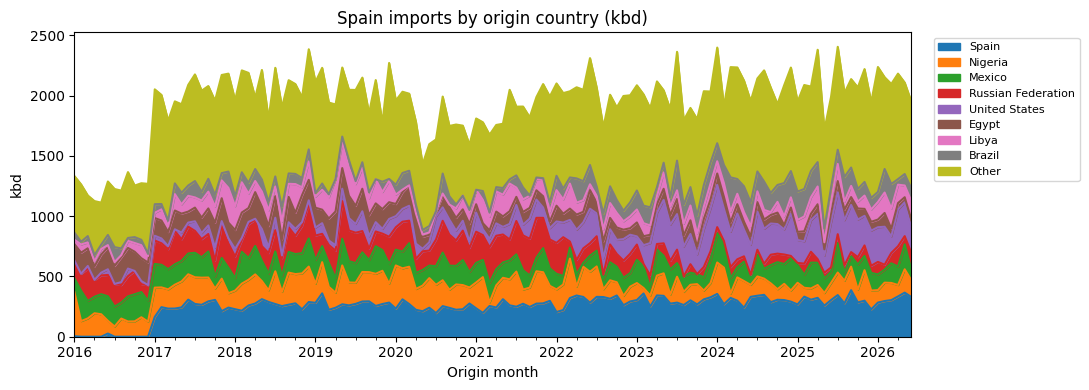

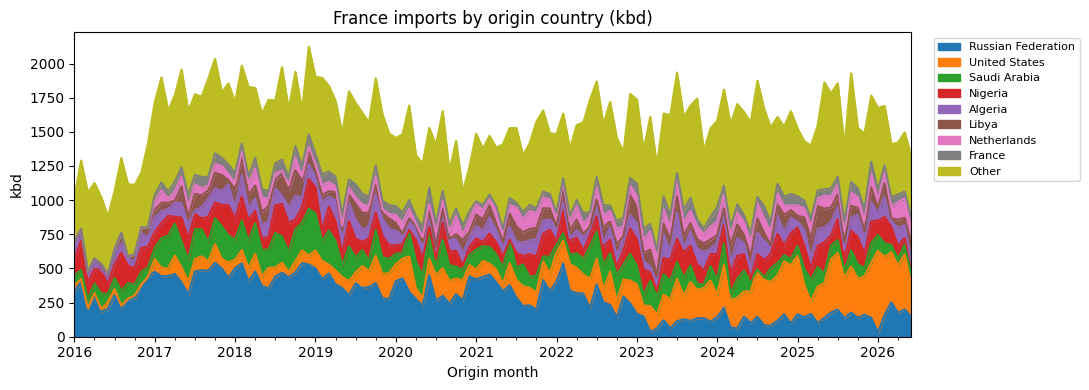

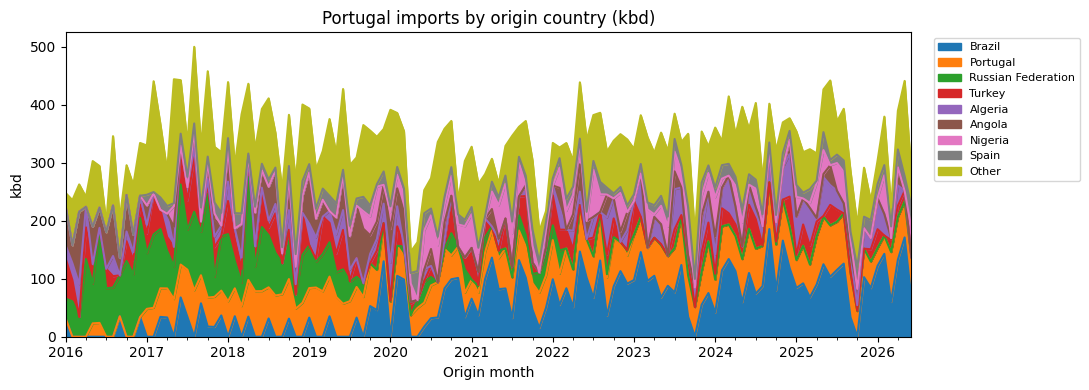

In [25]:
def origin_mix_monthly(country: str) -> pd.DataFrame:
    df = q(
        f"""
        SELECT
          {MONTH} AS month,
          COALESCE("Country (origin)", '(unknown)') AS origin_country,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          AND "Date (origin)" IS NOT NULL
        GROUP BY 1, 2
        HAVING month >= '2016-01' AND month <= ?
        """,
        [STATUS, country, SEASONALITY_END],
    )
    return add_kbd(df)


def plot_origin_stack_monthly(country: str, top_n: int = 8):
    df = origin_mix_monthly(country)
    plot_df = top_n_bucket(df, "origin_country", "volume_kbd", top_n)
    wide = (
        plot_df.groupby(["month", "origin_country"], as_index=False)["volume_kbd"]
        .sum()
        .assign(month=lambda x: month_index(x["month"]))
        .pivot(index="month", columns="origin_country", values="volume_kbd")
        .fillna(0)
        .sort_index()
    )
    totals = df.groupby("origin_country")["volume_kbd"].sum().sort_values(ascending=False)
    ordered = [c for c in totals.head(top_n).index if c in wide.columns]
    if "Other" in wide.columns:
        ordered.append("Other")
    wide = wide.reindex(columns=ordered)
    stacked_area_kbd(wide, f"{country} imports by origin country (kbd)")
    return wide


origin_tables = {c: plot_origin_stack_monthly(c) for c in COUNTRIES}

## 4. Family mix (monthly, kbd)

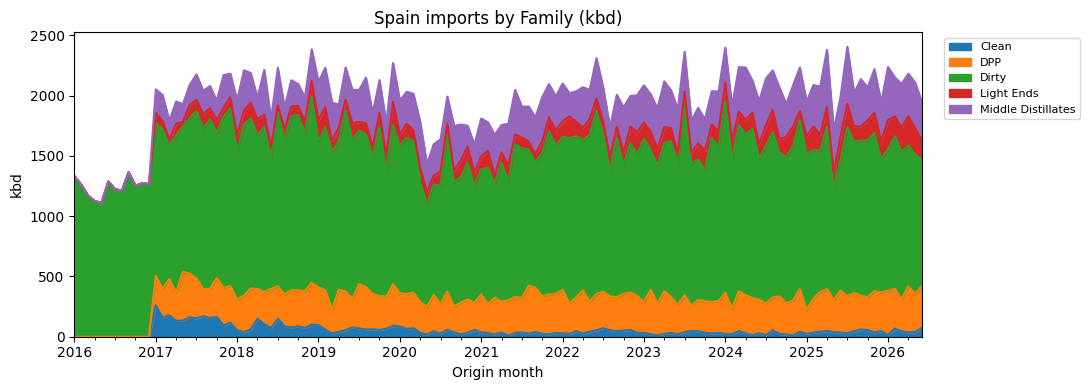

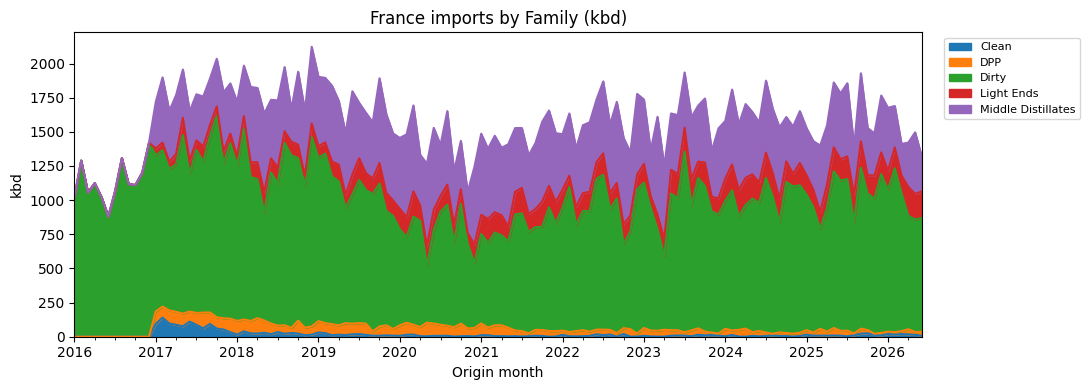

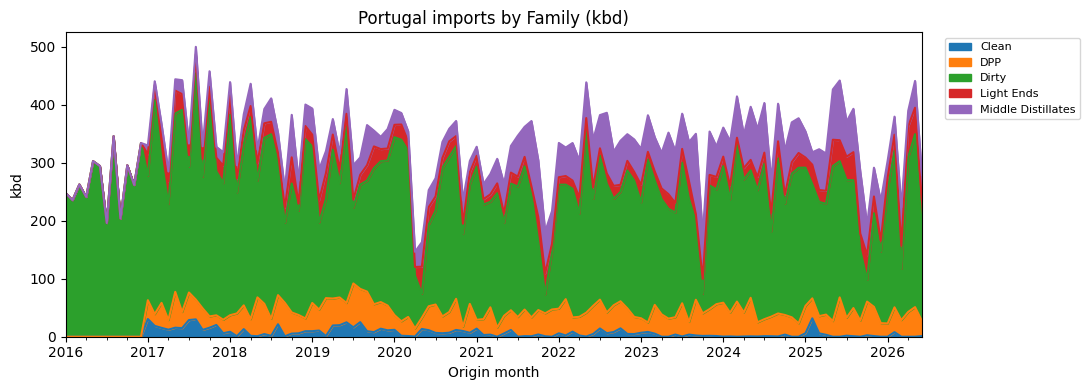

In [26]:
def family_mix_monthly(country: str) -> pd.DataFrame:
    df = q(
        f"""
        SELECT
          {MONTH} AS month,
          COALESCE(Family, '(unknown)') AS family,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          AND "Date (origin)" IS NOT NULL
        GROUP BY 1, 2
        HAVING month >= '2016-01' AND month <= ?
        """,
        [STATUS, country, SEASONALITY_END],
    )
    return add_kbd(df)


def plot_family_stack_monthly(country: str):
    df = family_mix_monthly(country)
    wide = (
        df.assign(month=lambda x: month_index(x["month"]))
        .pivot(index="month", columns="family", values="volume_kbd")
        .fillna(0)
        .sort_index()
    )
    stacked_area_kbd(wide, f"{country} imports by Family (kbd)")
    return wide


family_tables = {c: plot_family_stack_monthly(c) for c in COUNTRIES}

## 5. Seasonality by year (canonical products, kbd)

Small-multiples: **calendar month** on x, **one line per year**, panels = Kpler products.
Same pattern as the demand dashboards (historical years muted; prior year marked; current year bold red).

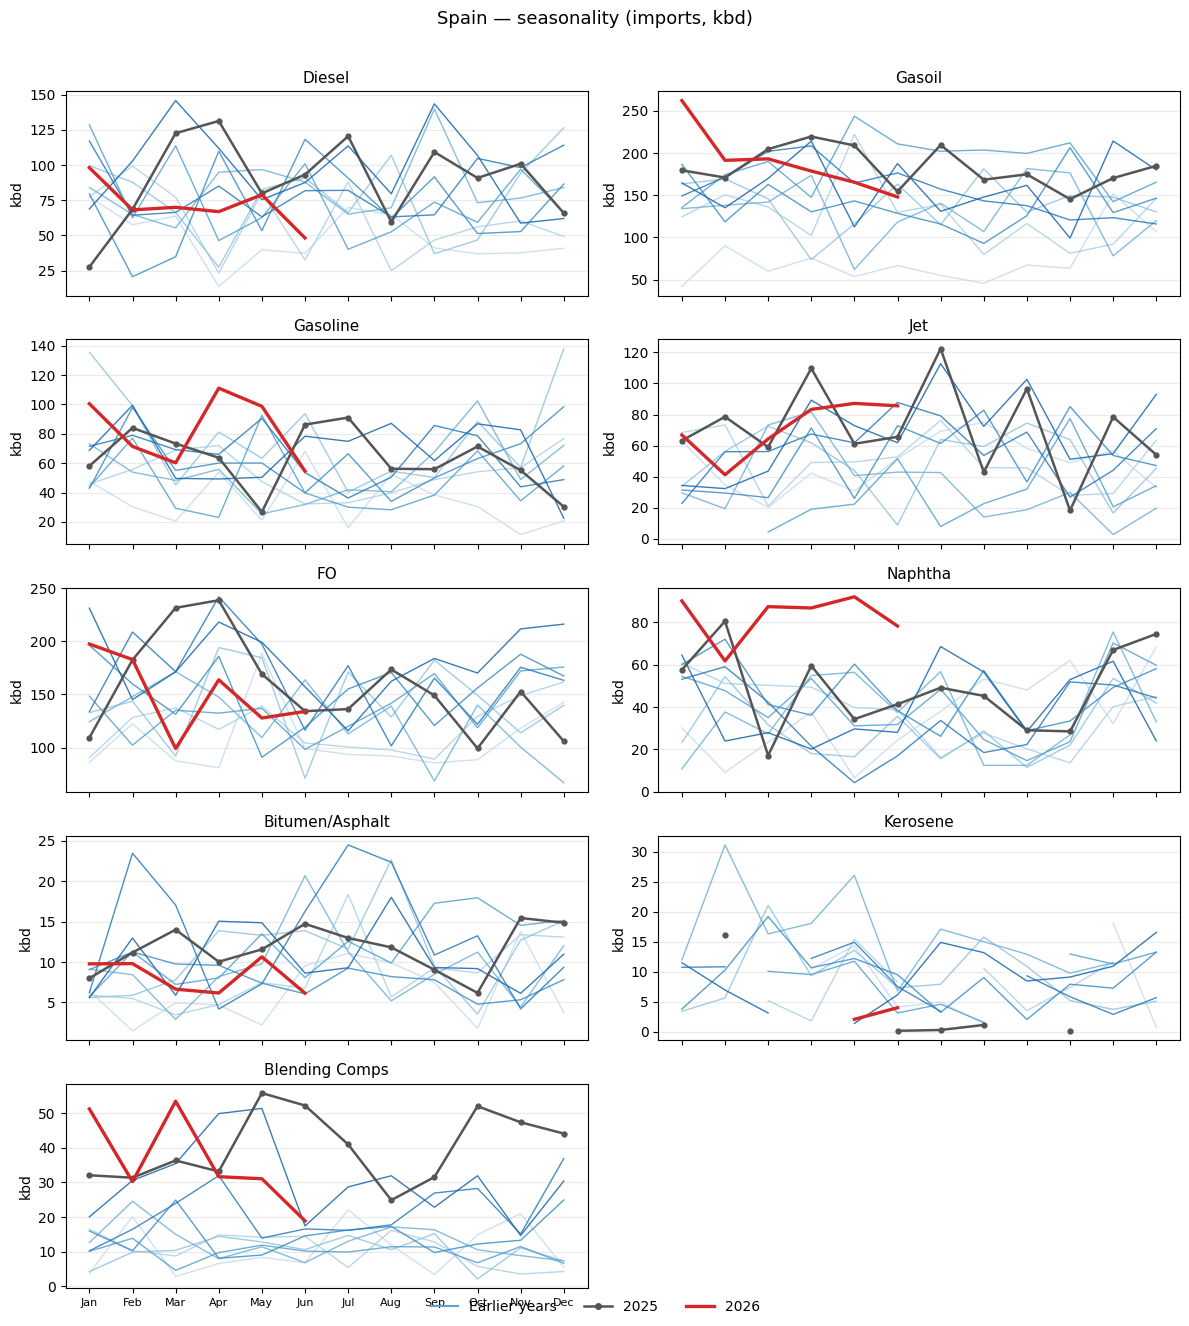

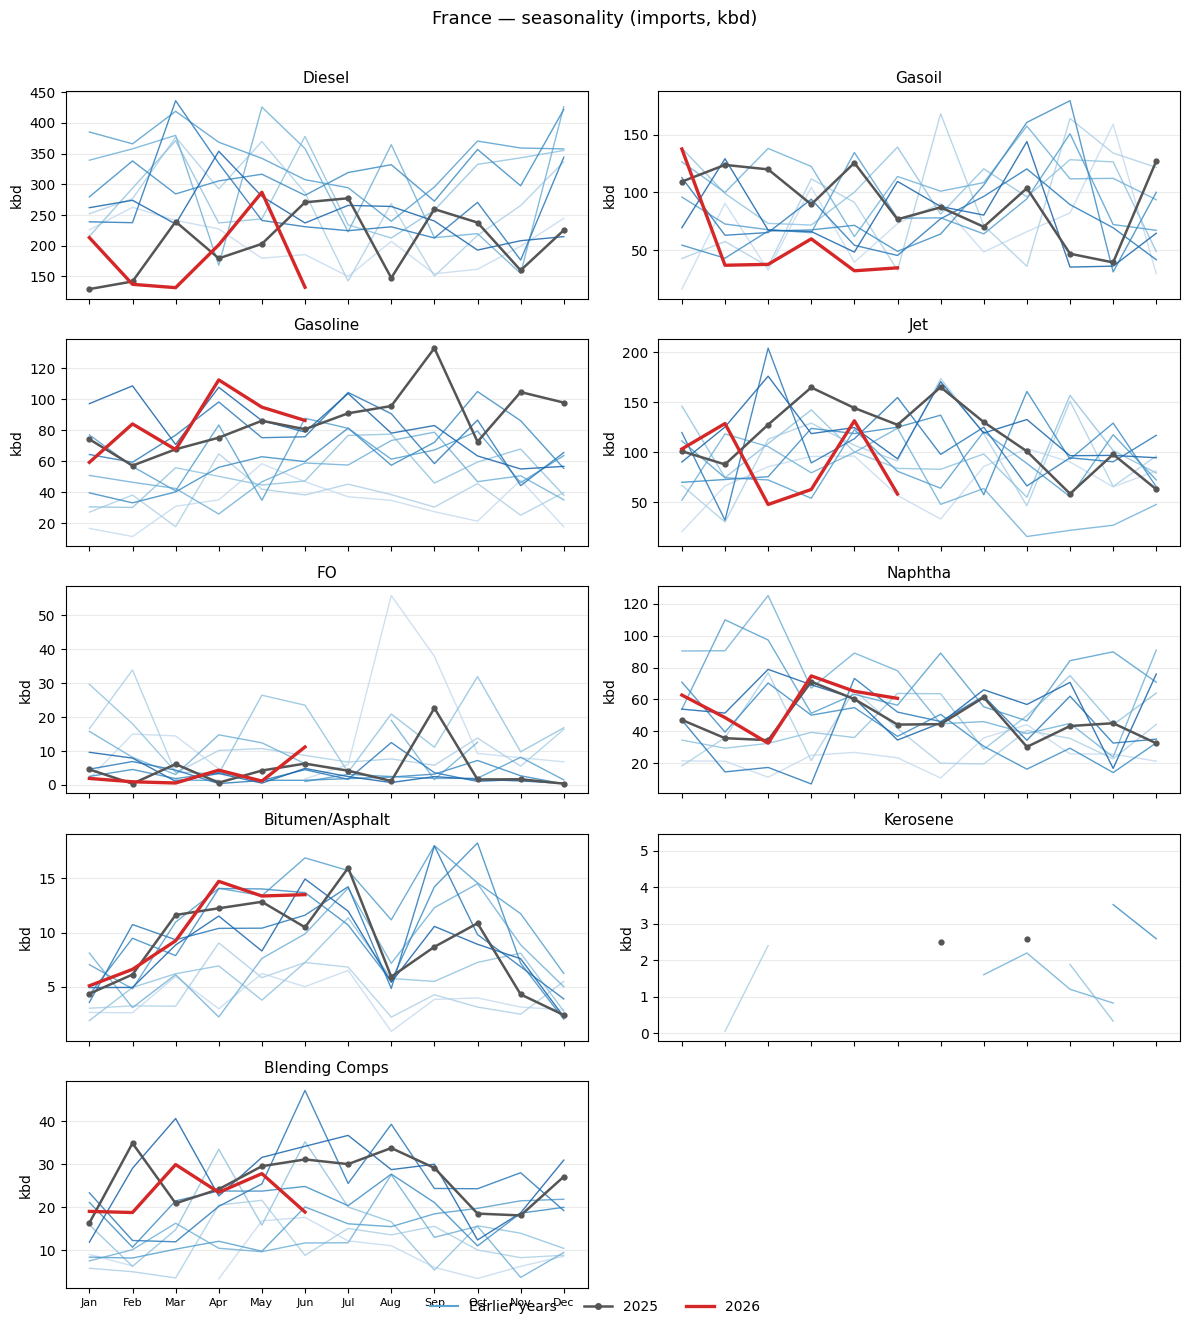

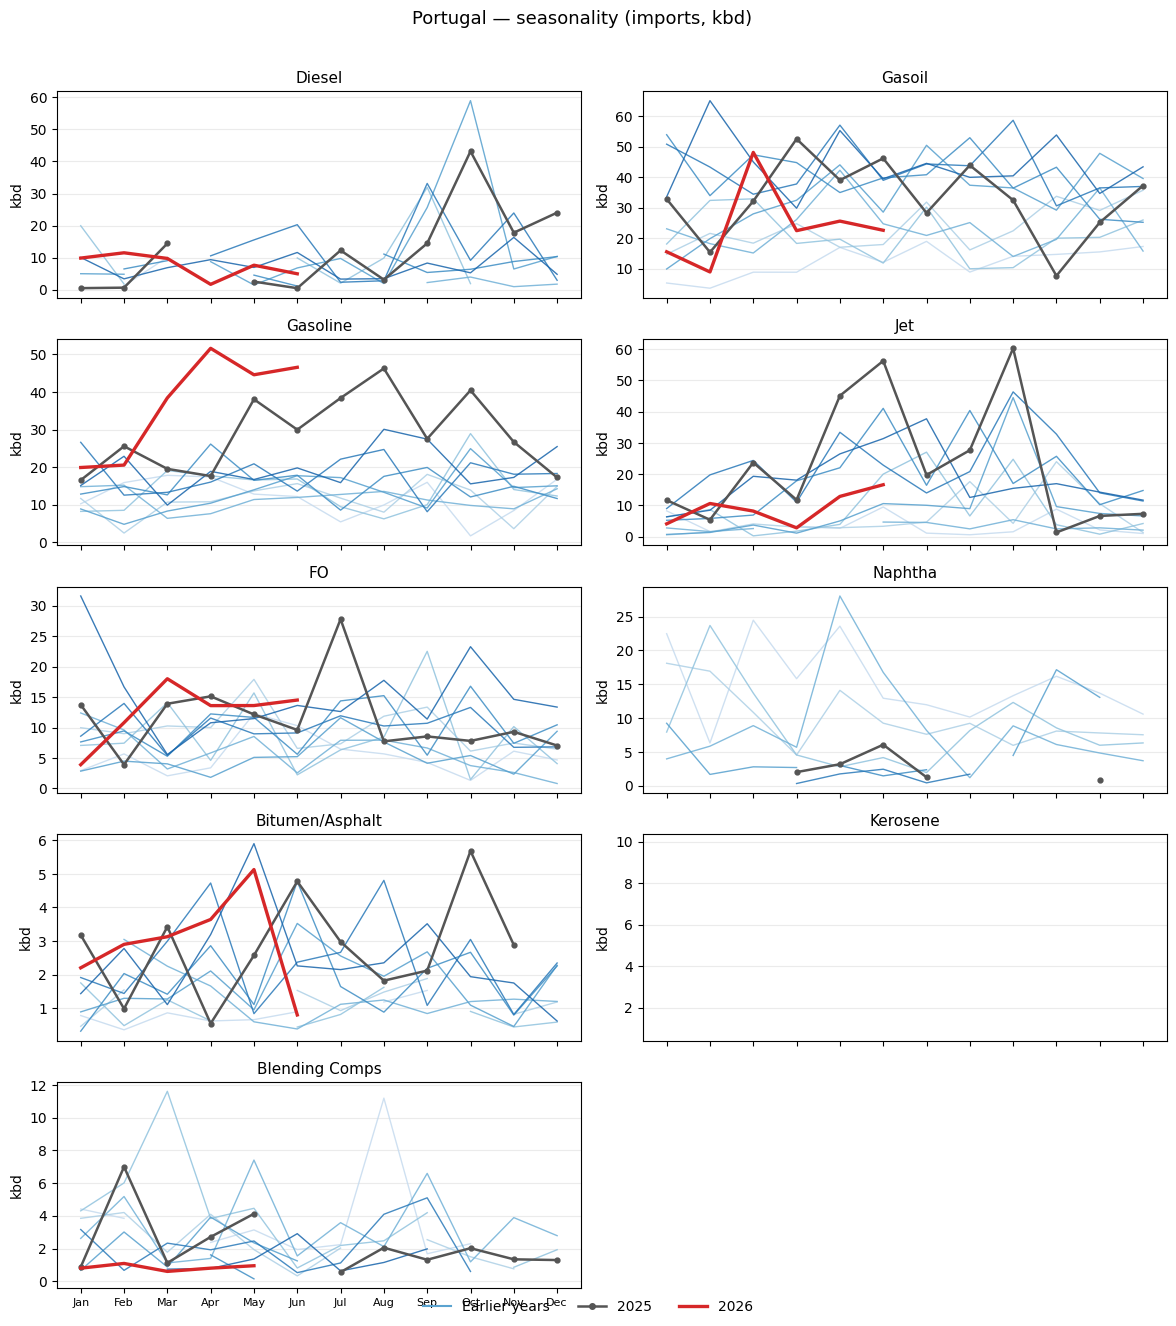

In [27]:
def product_month_year(country: str, products: list[str] | None = None) -> pd.DataFrame:
    products = products or SEASONALITY_PRODUCTS
    ph = country_placeholders(len(products))
    df = q(
        f"""
        SELECT
          {MONTH} AS month,
          {YEAR} AS year,
          {CAL_MONTH} AS cal_month,
          COALESCE(Product, '(blank)') AS product,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          AND COALESCE(Product, '(blank)') IN ({ph})
          AND "Date (origin)" IS NOT NULL
        GROUP BY 1, 2, 3, 4
        HAVING month >= '2016-01' AND month <= ?
        """,
        [STATUS, country, *products, SEASONALITY_END],
    )
    return add_kbd(df)


def plot_seasonality_by_year(
    country: str,
    products: list[str] | None = None,
    cols: int = 2,
    min_total_kbd_days: float = 5.0,
):
    """
    Faceted YoY seasonality in kbd.
    Drops products with almost no volume so empty panels are avoided.
    """
    products = list(products or SEASONALITY_PRODUCTS)
    if not INCLUDE_CRUDE:
        products = [p for p in products if p not in {"Crude", "Condensate"}]
    df = product_month_year(country, products)
    # Keep products that actually move in this market
    kept = (
        df.groupby("product")["volume_kbd"]
        .sum()
        .loc[lambda s: s >= min_total_kbd_days]
        .sort_values(ascending=False)
    )
    products = [p for p in products if p in kept.index]
    if not products:
        print(f"{country}: no products above volume threshold")
        return None

    n = len(products)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 2.6 * rows), sharex=True)
    axes = np.atleast_2d(axes)

    hist_years = sorted(y for y in df["year"].unique() if y not in (PRIOR_YEAR, HIGHLIGHT_YEAR))
    cmap = plt.cm.Blues
    hist_colors = {
        y: cmap(0.25 + 0.55 * i / max(len(hist_years) - 1, 1))
        for i, y in enumerate(hist_years)
    }

    for i, product in enumerate(products):
        r, c = divmod(i, cols)
        ax = axes[r, c]
        sub = df[df["product"] == product]

        for y in hist_years:
            sy = sub[sub["year"] == y].set_index("cal_month").reindex(range(1, 13))
            ax.plot(
                range(1, 13),
                sy["volume_kbd"].to_numpy(),
                color=hist_colors[y],
                lw=1.0,
                alpha=0.85,
            )

        if PRIOR_YEAR in sub["year"].values:
            sy = sub[sub["year"] == PRIOR_YEAR].set_index("cal_month").reindex(range(1, 13))
            ax.plot(
                range(1, 13),
                sy["volume_kbd"].to_numpy(),
                color="#555555",
                lw=1.8,
                marker="o",
                ms=3.5,
            )

        if HIGHLIGHT_YEAR in sub["year"].values:
            sy = sub[sub["year"] == HIGHLIGHT_YEAR].set_index("cal_month").reindex(range(1, 13))
            ax.plot(
                range(1, 13),
                sy["volume_kbd"].to_numpy(),
                color="#d62728",
                lw=2.4,
            )

        ax.set_title(product, fontsize=11)
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(MONTH_LABELS, fontsize=8)
        ax.set_ylabel("kbd")
        ax.grid(True, axis="y", alpha=0.25)

    # Hide unused axes
    for j in range(n, rows * cols):
        r, c = divmod(j, cols)
        axes[r, c].set_visible(False)

    legend_handles = [
        Line2D([0], [0], color=cmap(0.55), lw=1.5, label="Earlier years"),
        Line2D([0], [0], color="#555555", lw=1.8, marker="o", ms=4, label=str(PRIOR_YEAR)),
        Line2D([0], [0], color="#d62728", lw=2.4, label=str(HIGHLIGHT_YEAR)),
    ]
    fig.legend(handles=legend_handles, loc="lower center", ncol=3, frameon=False)
    fig.suptitle(f"{country} — seasonality (imports, kbd)", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()
    return df


seasonality_data = {c: plot_seasonality_by_year(c) for c in COUNTRIES}

## 6. Product-level insights by country

For each market: top products, monthly product stack (kbd), **most important terminal per product**,
product×origin concentration, and **import/export stacked-bar panels**:

1. Panel — imports | exports **by product**
2. Panel — imports by **origin country** | exports by **destination country**


In [28]:
def top_products(country: str, n: int = 12, include_crude: bool | None = None) -> pd.DataFrame:
    crude = crude_sql_filter(include_crude)
    return q(
        f"""
        SELECT
          COALESCE(Product, '(blank)') AS product,
          COALESCE(Family, '(unknown)') AS family,
          COALESCE("Group", '(blank)') AS product_group,
          COUNT(*) AS trades,
          ROUND(SUM({VOL}) / 1e6, 2) AS volume_mb,
          ROUND(100.0 * SUM({VOL}) / SUM(SUM({VOL})) OVER (), 1) AS pct_of_imports
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          {crude}
        GROUP BY 1, 2, 3
        ORDER BY SUM({VOL}) DESC
        LIMIT ?
        """,
        [STATUS, country, n],
    )


def product_mix_monthly(country: str, include_crude: bool | None = None) -> pd.DataFrame:
    crude = crude_sql_filter(include_crude)
    df = q(
        f"""
        SELECT
          {MONTH} AS month,
          COALESCE(Product, '(blank)') AS product,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          AND "Date (origin)" IS NOT NULL
          {crude}
        GROUP BY 1, 2
        HAVING month >= '2016-01' AND month <= ?
        """,
        [STATUS, country, SEASONALITY_END],
    )
    return add_kbd(df)


def top_terminal_by_product(
    country: str, n_products: int = 12, include_crude: bool | None = None
) -> pd.DataFrame:
    """For each top product, the #1 destination installation by volume."""
    crude = crude_sql_filter(include_crude)
    return q(
        f"""
        WITH product_rank AS (
          SELECT
            COALESCE(Product, '(blank)') AS product,
            SUM({VOL}) AS product_bbl,
            ROW_NUMBER() OVER (ORDER BY SUM({VOL}) DESC) AS product_rn
          FROM trades
          WHERE "Trade status" = ?
            AND "Country (destination)" = ?
            {crude}
          GROUP BY 1
        ),
        by_term AS (
          SELECT
            COALESCE(Product, '(blank)') AS product,
            "Installation Destination" AS installation,
            SUM({VOL}) AS term_bbl,
            COUNT(*) AS trades,
            ROW_NUMBER() OVER (
              PARTITION BY COALESCE(Product, '(blank)')
              ORDER BY SUM({VOL}) DESC
            ) AS term_rn
          FROM trades
          WHERE "Trade status" = ?
            AND "Country (destination)" = ?
            AND "Installation Destination" IS NOT NULL
            AND "Installation Destination" <> ''
            {crude}
          GROUP BY 1, 2
        )
        SELECT
          p.product,
          t.installation AS top_terminal,
          ROUND(t.term_bbl / 1e6, 2) AS terminal_mb,
          ROUND(100.0 * t.term_bbl / p.product_bbl, 1) AS pct_of_product,
          ROUND(p.product_bbl / 1e6, 2) AS product_mb,
          t.trades AS terminal_trades
        FROM product_rank p
        JOIN by_term t ON p.product = t.product AND t.term_rn = 1
        WHERE p.product_rn <= ?
        ORDER BY p.product_rn
        """,
        [STATUS, country, STATUS, country, n_products],
    )


def product_origin_matrix(
    country: str,
    top_products_n: int = 8,
    top_origins_n: int = 8,
    include_crude: bool | None = None,
) -> pd.DataFrame:
    crude = crude_sql_filter(include_crude)
    df = q(
        f"""
        SELECT
          COALESCE(Product, '(blank)') AS product,
          COALESCE("Country (origin)", '(unknown)') AS origin_country,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          {crude}
        GROUP BY 1, 2
        """,
        [STATUS, country],
    )
    top_p = df.groupby("product")["volume_kb"].sum().nlargest(top_products_n).index
    top_o = df.groupby("origin_country")["volume_kb"].sum().nlargest(top_origins_n).index
    sub = df[df["product"].isin(top_p)].copy()
    sub["origin_country"] = sub["origin_country"].where(sub["origin_country"].isin(top_o), "Other")
    return (
        sub.groupby(["product", "origin_country"], as_index=False)["volume_kb"]
        .sum()
        .pivot(index="product", columns="origin_country", values="volume_kb")
        .fillna(0)
    )




def _monthly_mix(
    country: str,
    *,
    direction: str,
    dim: str,
    include_crude: bool | None = None,
    start: str | None = None,
    end: str | None = None,
    top_n: int = 8,
) -> pd.DataFrame:
    """
    Monthly kbd mix for stacked bars.
    direction: 'import' | 'export'
    dim: 'product' | 'partner'  (partner = origin for imports, destination for exports)
    """
    crude = crude_sql_filter(include_crude)
    start = start or SANKEY_START
    end = end or SANKEY_END

    if direction == "import":
        geo = '"Country (destination)" = ?'
        if dim == "product":
            cat = "COALESCE(Product, '(blank)') AS category"
        elif dim == "partner":
            cat = "COALESCE(\"Country (origin)\", '(unknown)') AS category"
        else:
            raise ValueError(dim)
    elif direction == "export":
        geo = '"Country (origin)" = ?'
        if dim == "product":
            cat = "COALESCE(Product, '(blank)') AS category"
        elif dim == "partner":
            cat = "COALESCE(\"Country (destination)\", '(unknown)') AS category"
        else:
            raise ValueError(dim)
    else:
        raise ValueError(direction)

    df = q(
        f"""
        SELECT
          {MONTH} AS month,
          {cat},
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND {geo}
          AND {MONTH} >= ? AND {MONTH} <= ?
          {crude}
        GROUP BY 1, 2
        """,
        [STATUS, country, start, end],
    )
    if df.empty:
        return df
    df = add_kbd(df)
    df = top_n_bucket(df, "category", "volume_kbd", top_n)
    return (
        df.groupby(["month", "category"], as_index=False)["volume_kbd"]
        .sum()
        .sort_values("month")
    )


def _category_colors(categories: list[str]) -> dict[str, tuple]:
    """Stable color per category so import/export charts share the same palette."""
    cmap = plt.cm.tab20
    colors: dict[str, tuple] = {}
    i = 0
    for cat in categories:
        if cat == "Other":
            colors[cat] = (0.65, 0.65, 0.65, 1.0)
            continue
        colors[cat] = cmap(i % 20)
        i += 1
    return colors


def _plot_stacked_bar_ax(ax, wide: pd.DataFrame, title: str, color_map: dict[str, tuple]):
    if wide.empty:
        ax.set_title(title + " (no data)")
        ax.axis("off")
        return
    plot_colors = [color_map[c] for c in wide.columns]
    wide.plot(kind="bar", stacked=True, ax=ax, width=0.9, legend=False, color=plot_colors)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("kbd")
    ax.set_xlabel("")
    n = len(wide)
    step = max(n // 10, 1)
    ax.set_xticks(range(0, n, step))
    ax.set_xticklabels([str(wide.index[i]) for i in range(0, n, step)], rotation=45, ha="right", fontsize=7)
    ax.grid(True, axis="y", alpha=0.25)


def plot_country_ie_panels(
    country: str,
    *,
    include_crude: bool | None = None,
    top_n: int = 8,
    start: str | None = None,
    end: str | None = None,
):
    """
    Two panels, each with import / export subplots stacked vertically (monthly kbd):
      Panel 1 — by product
      Panel 2 — by partner country (origin for imports, destination for exports)

    Series colors are shared across the import and export charts in a panel.
    """
    label = crude_label(include_crude)
    specs = [
        ("product", f"{country} — by product ({label})"),
        ("partner", f"{country} — by partner country ({label})"),
    ]

    for dim, panel_title in specs:
        wides: dict[str, pd.DataFrame] = {}
        for direction in ("import", "export"):
            mix = _monthly_mix(
                country,
                direction=direction,
                dim=dim,
                include_crude=include_crude,
                start=start,
                end=end,
                top_n=top_n,
            )
            if mix.empty:
                wides[direction] = pd.DataFrame()
                continue
            wide = (
                mix.assign(month=lambda x: month_index(x["month"]))
                .pivot(index="month", columns="category", values="volume_kbd")
                .fillna(0)
                .sort_index()
            )
            wides[direction] = wide

        totals: dict[str, float] = {}
        for wide in wides.values():
            if wide.empty:
                continue
            for cat, val in wide.sum().items():
                totals[cat] = totals.get(cat, 0.0) + float(val)
        ordered = sorted(
            (c for c in totals if c != "Other"),
            key=lambda c: totals[c],
            reverse=True,
        )
        if "Other" in totals:
            ordered.append("Other")
        color_map = _category_colors(ordered)

        for direction in ("import", "export"):
            if wides[direction].empty:
                continue
            wides[direction] = wides[direction].reindex(columns=ordered, fill_value=0)

        fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=False)
        for ax, direction, side_title in [
            (axes[0], "import", "Imports"),
            (axes[1], "export", "Exports"),
        ]:
            dim_label = (
                "origin country"
                if dim == "partner" and direction == "import"
                else "destination country"
                if dim == "partner"
                else "product"
            )
            _plot_stacked_bar_ax(
                ax,
                wides[direction],
                f"{side_title} by {dim_label}",
                color_map,
            )

        if ordered:
            handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[c]) for c in ordered]
            fig.legend(
                handles,
                ordered,
                loc="upper left",
                bbox_to_anchor=(1.01, 0.98),
                fontsize=7,
                title=dim,
            )

        if dim == "partner":
            fig.suptitle(
                f"{panel_title}\n"
                "top: imports by origin country · bottom: exports by destination country",
                fontsize=12,
                y=1.02,
            )
        else:
            fig.suptitle(panel_title, fontsize=12, y=1.01)
        plt.tight_layout()
        plt.show()


def explore_country_products(country: str, top_n_products: int = 8, include_crude: bool | None = None):
    print("=" * 72)
    print(f"{country.upper()} — PRODUCT INSIGHTS ({crude_label(include_crude)})")
    print("=" * 72)

    tops = top_products(country, include_crude=include_crude)
    print("Top products (lifetime mb)")
    display(tops)

    print("Most important terminal by product (regional concentration)")
    term_by_prod = top_terminal_by_product(country, include_crude=include_crude)
    display(term_by_prod)

    # Monthly stack of top products in kbd
    mix = product_mix_monthly(country, include_crude=include_crude)
    plot_df = top_n_bucket(mix, "product", "volume_kbd", top_n_products)
    wide = (
        plot_df.groupby(["month", "product"], as_index=False)["volume_kbd"]
        .sum()
        .assign(month=lambda x: month_index(x["month"]))
        .pivot(index="month", columns="product", values="volume_kbd")
        .fillna(0)
        .sort_index()
    )
    ordered = [p for p in tops["product"].head(top_n_products) if p in wide.columns]
    if "Other" in wide.columns:
        ordered.append("Other")
    wide = wide.reindex(columns=[c for c in ordered if c in wide.columns])
    stacked_area_kbd(wide, f"{country} imports by Product (kbd)")

    # Country-specific seasonality panels (same style as §5)
    print(f"{country} — product seasonality (kbd)")
    plot_seasonality_by_year(country)

    # Product × origin share heatmap
    matrix = product_origin_matrix(country, include_crude=include_crude)
    share = matrix.div(matrix.sum(axis=1).replace(0, np.nan), axis=0) * 100
    fig, ax = plt.subplots(figsize=(10, max(3, 0.45 * len(share))))
    im = ax.imshow(share.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(len(share.columns)))
    ax.set_xticklabels(share.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(share.index)))
    ax.set_yticklabels(share.index, fontsize=8)
    ax.set_title(f"{country} — origin share within each product (% of product volume)")
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="%")
    plt.tight_layout()
    plt.show()

    print(f"{country} — import/export stacked bars (monthly kbd)")
    plot_country_ie_panels(country, include_crude=include_crude)

    return {
        "top_products": tops,
        "top_terminal_by_product": term_by_prod,
        "monthly_kbd": wide,
        "origin_share": share,
    }


### 6a. Spain — products & terminals

SPAIN — PRODUCT INSIGHTS (excl. crude)
Top products (lifetime mb)


,product,family,product_group,trades,volume_mb,pct_of_imports
0,Gasoil,Middle Distillates,Gasoil/Diesel,4762,508.16,23.7
1,FO,DPP,Fuel Oils,3810,497.79,23.2
2,Diesel,Middle Distillates,Gasoil/Diesel,1262,262.89,12.2
3,Gasoline,Light Ends,Gasoline/Naphtha,2455,206.77,9.6
4,Jet,Middle Distillates,Kero/Jet,1125,181.11,8.4
5,Dirty Feedstocks,DPP,Fuel Oils,1060,146.41,6.8
6,Naphtha,Light Ends,Gasoline/Naphtha,1145,143.47,6.7
7,Blending Comps,Light Ends,Blendings,1382,65.26,3.0
8,SRFO,DPP,Fuel Oils,333,53.78,2.5
9,Bitumen/Asphalt,DPP,Resids,1606,34.82,1.6


Most important terminal by product (regional concentration)


,product,top_terminal,terminal_mb,pct_of_product,product_mb,terminal_trades
0,Gasoil,Oryx Las Palmas,58.21,11.5,508.16,333
1,FO,Vopak Algeciras,144.79,29.1,497.79,889
2,Diesel,Bilbao Oil Facilities,62.46,23.8,262.89,218
3,Gasoline,Vopak Terquimsa Barcelona,23.15,11.2,206.77,147
4,Jet,Gibraltar-San Roque Refinery,40.21,22.2,181.11,149
5,Dirty Feedstocks,Tarragona Refinery,28.24,19.3,146.41,178
6,Naphtha,Tarragona Refinery,90.79,63.3,143.47,557
7,Blending Comps,Barcelona 32A,6.69,10.2,65.26,77
8,SRFO,Repsol Cartagena Refinery,11.90,22.1,53.78,45
9,Bitumen/Asphalt,Cadiz,14.97,43.0,34.82,272


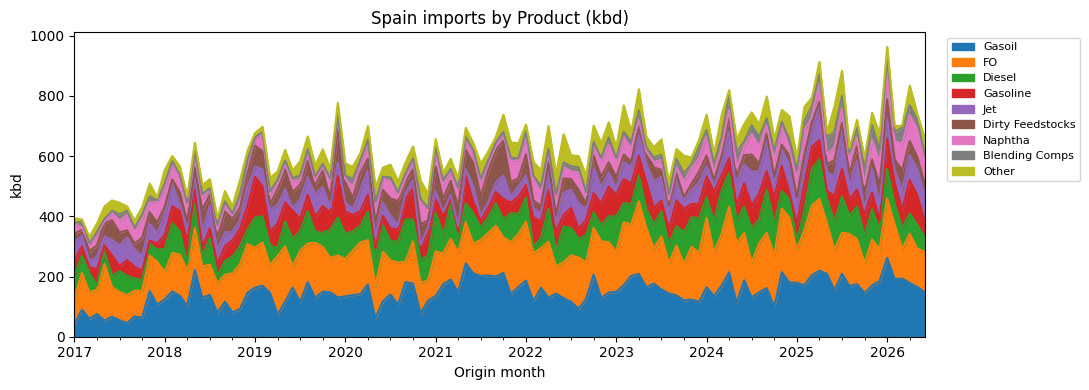

Spain — product seasonality (kbd)


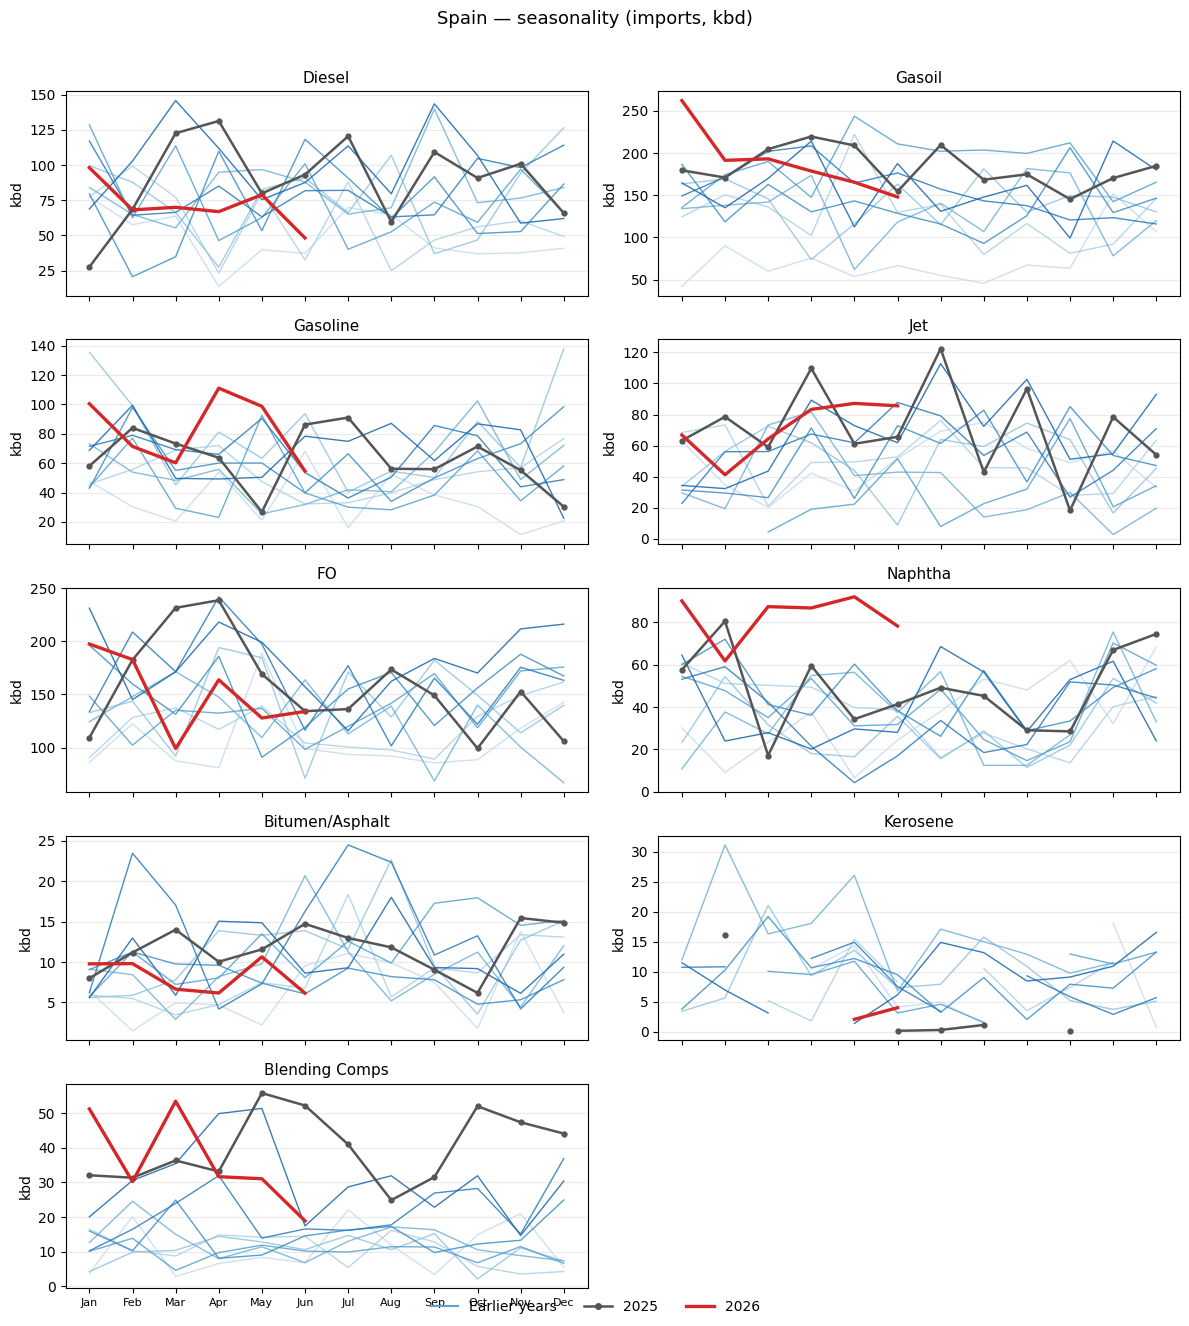

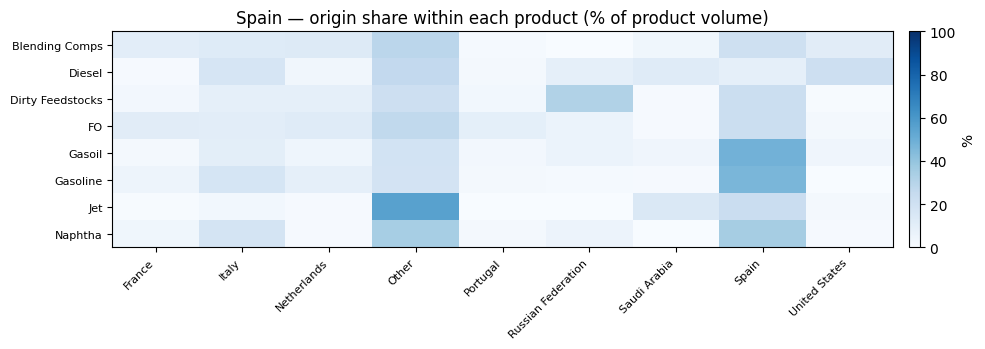

Spain — import/export stacked bars (monthly kbd)


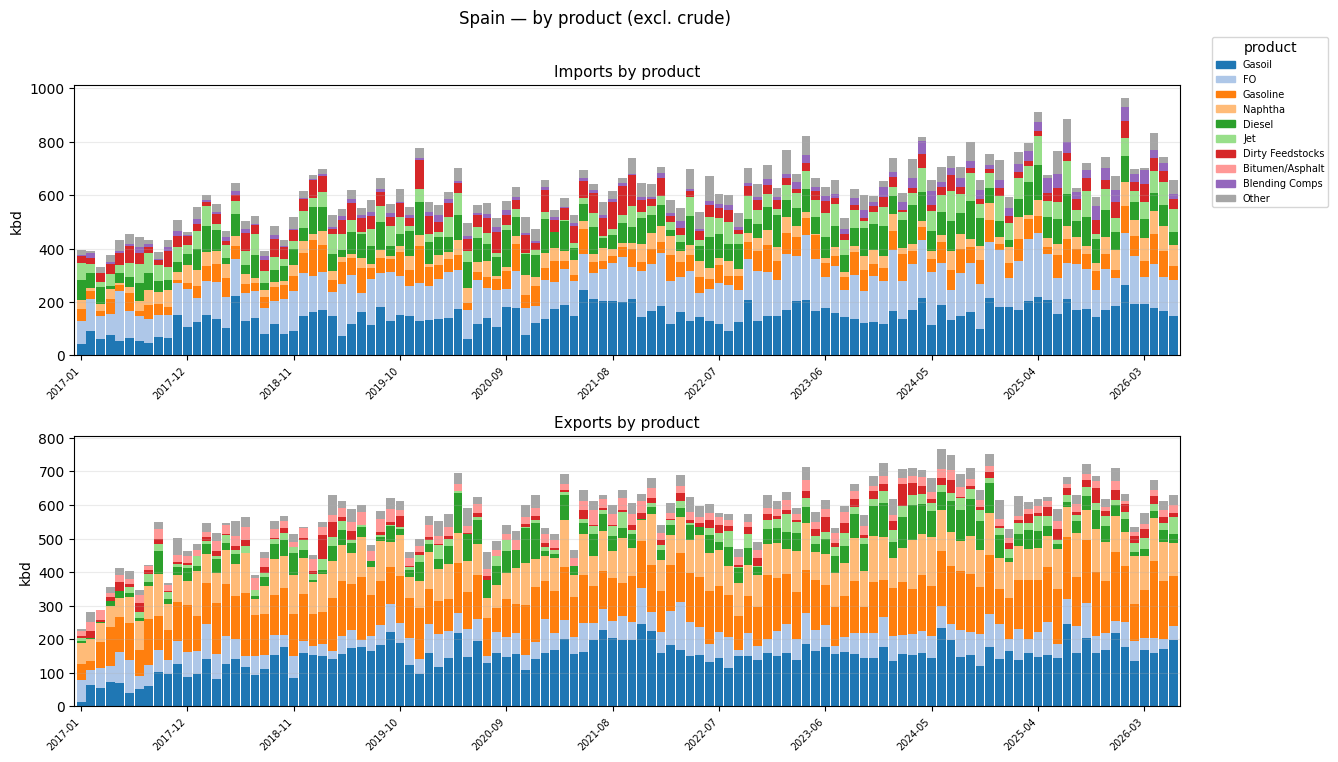

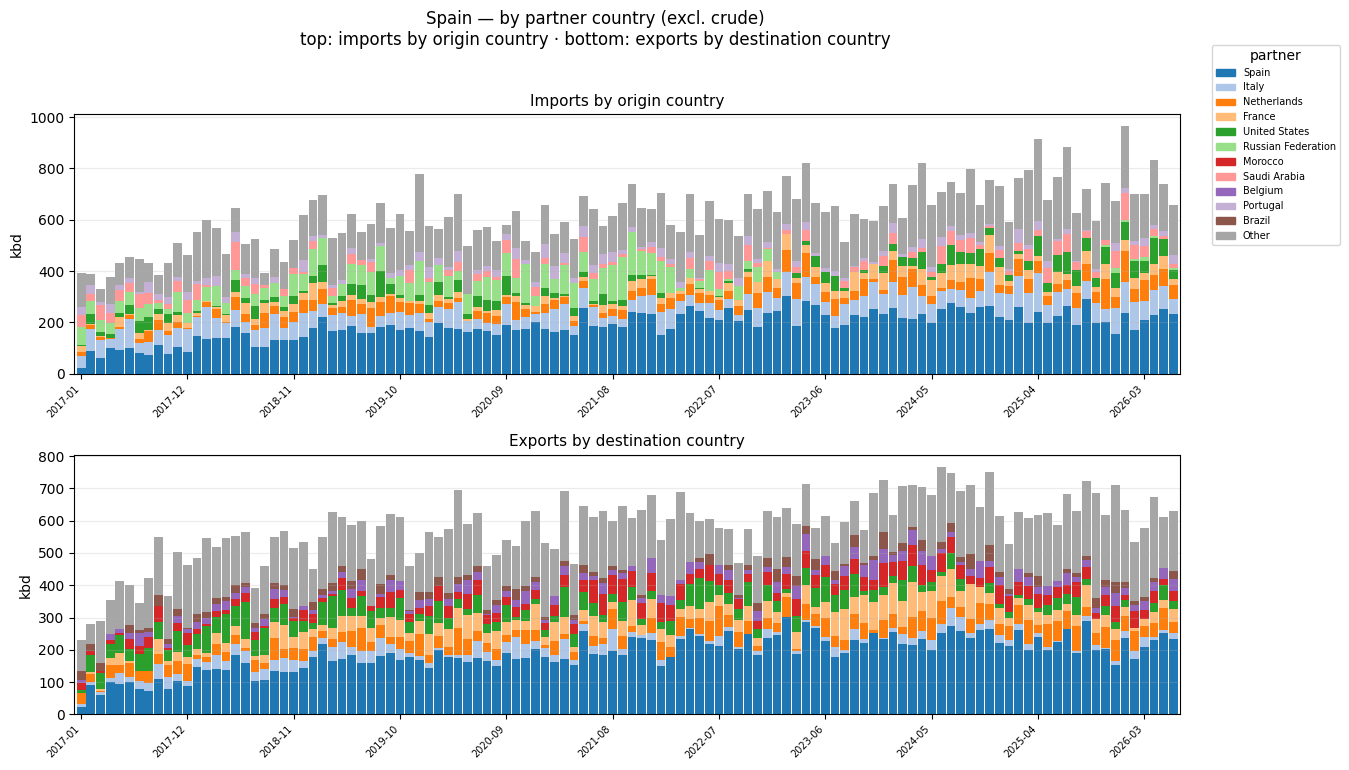

In [29]:
spain_products = explore_country_products("Spain")

### 6b. France — products & terminals

FRANCE — PRODUCT INSIGHTS (excl. crude)
Top products (lifetime mb)


,product,family,product_group,trades,volume_mb,pct_of_imports
0,Diesel,Middle Distillates,Gasoil/Diesel,4330,927.94,42.8
1,Jet,Middle Distillates,Kero/Jet,1401,336.27,15.5
2,Gasoil,Middle Distillates,Gasoil/Diesel,2100,299.52,13.8
3,Gasoline,Light Ends,Gasoline/Naphtha,5132,215.59,9.9
4,Naphtha,Light Ends,Gasoline/Naphtha,1286,169.38,7.8
5,Dirty Feedstocks,DPP,Fuel Oils,640,70.29,3.2
6,Blending Comps,Light Ends,Blendings,2076,63.90,2.9
7,Bitumen/Asphalt,DPP,Resids,1568,28.22,1.3
8,FO,DPP,Fuel Oils,348,25.66,1.2
9,SRFO,DPP,Fuel Oils,99,16.12,0.7


Most important terminal by product (regional concentration)


,product,top_terminal,terminal_mb,pct_of_product,product_mb,terminal_trades
0,Diesel,Fos Sur Mer,186.41,20.1,927.94,530
1,Jet,Le Havre,289.55,86.1,336.27,730
2,Gasoil,Fos Sur Mer,78.50,26.2,299.52,280
3,Gasoline,Fos Sur Mer,28.07,13.0,215.59,335
4,Naphtha,La Mede & Fluxys Lavera,80.65,47.6,169.38,453
5,Dirty Feedstocks,North Atlantic Port Jerome Refinery,31.93,45.4,70.29,301
6,Blending Comps,Fos Sur Mer,12.27,19.2,63.90,258
7,Bitumen/Asphalt,Chane Nantes,6.99,24.8,28.22,397
8,FO,La Mede & Fluxys Lavera,5.48,21.4,25.66,31
9,SRFO,La Mede & Fluxys Lavera,10.72,66.5,16.12,61


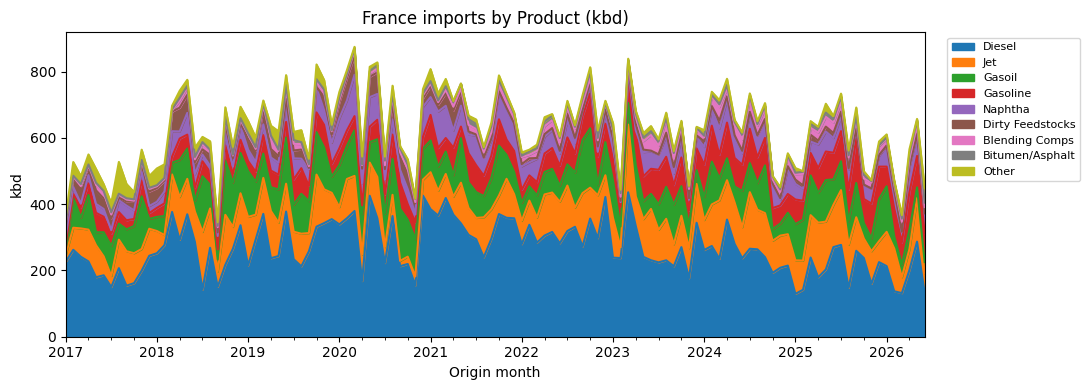

France — product seasonality (kbd)


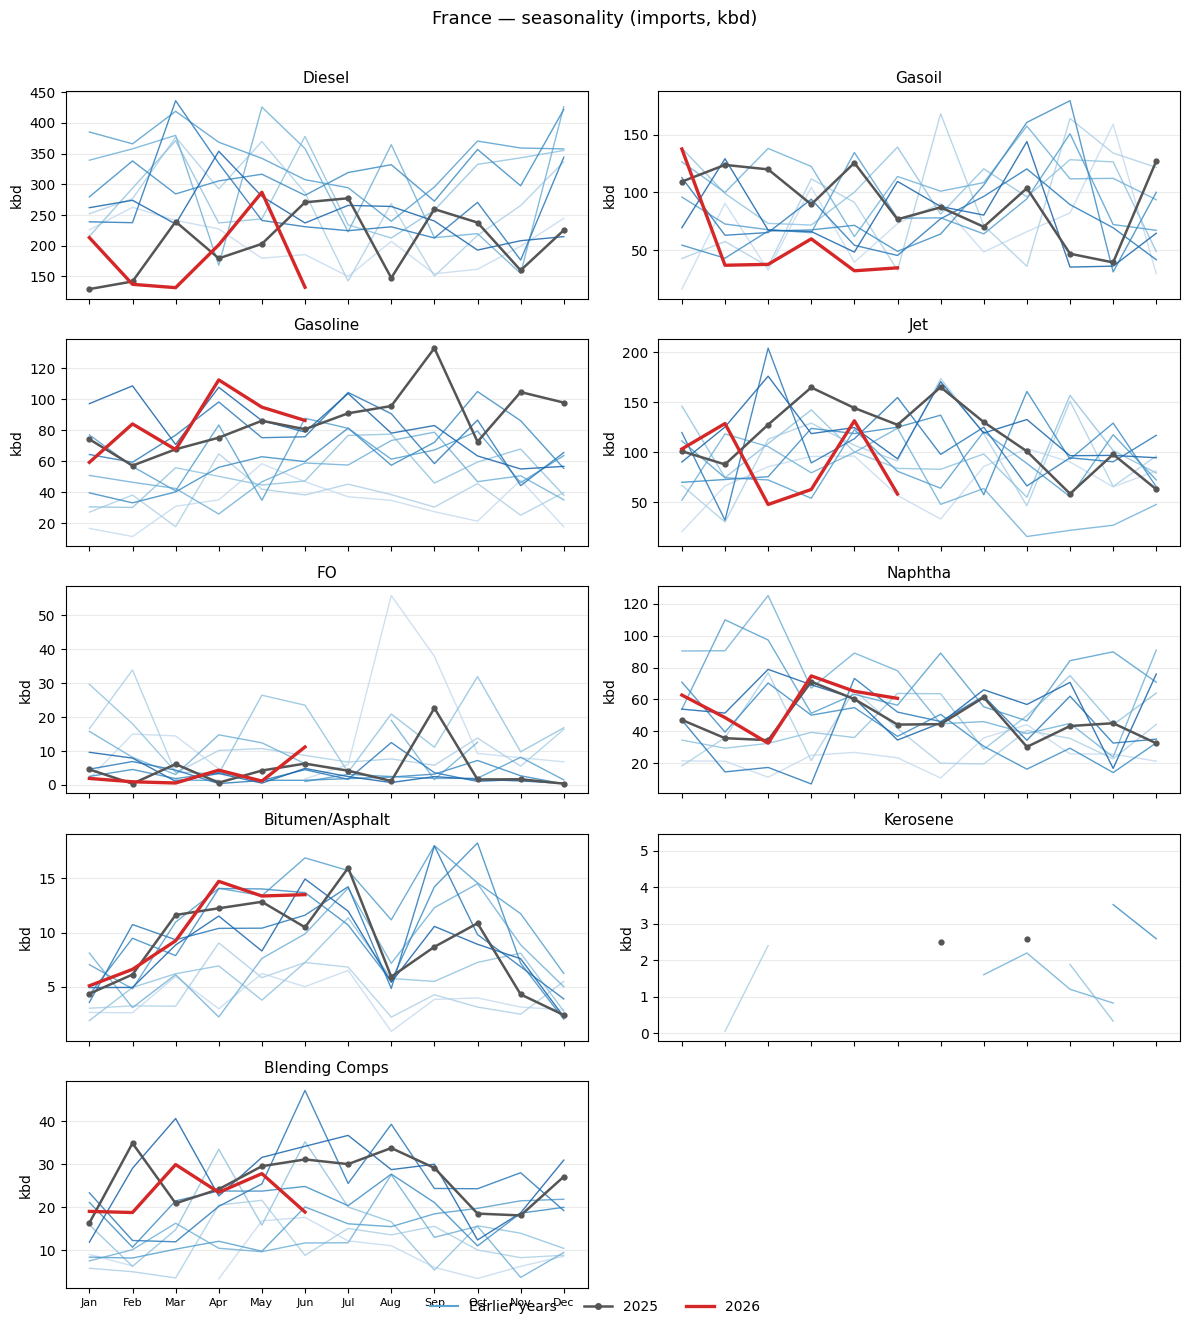

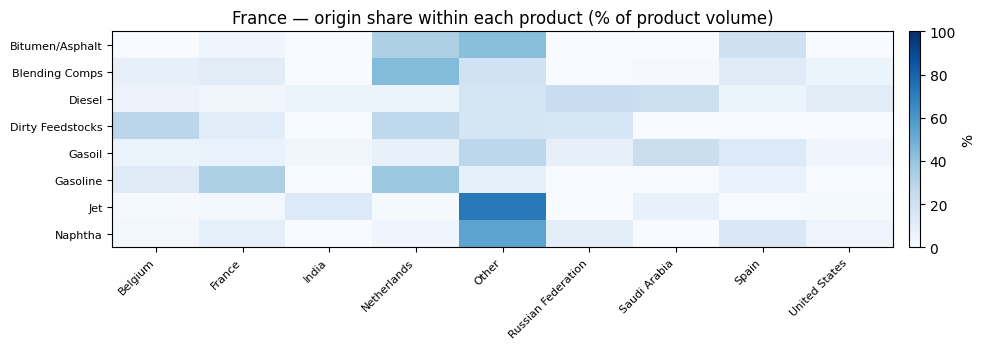

France — import/export stacked bars (monthly kbd)


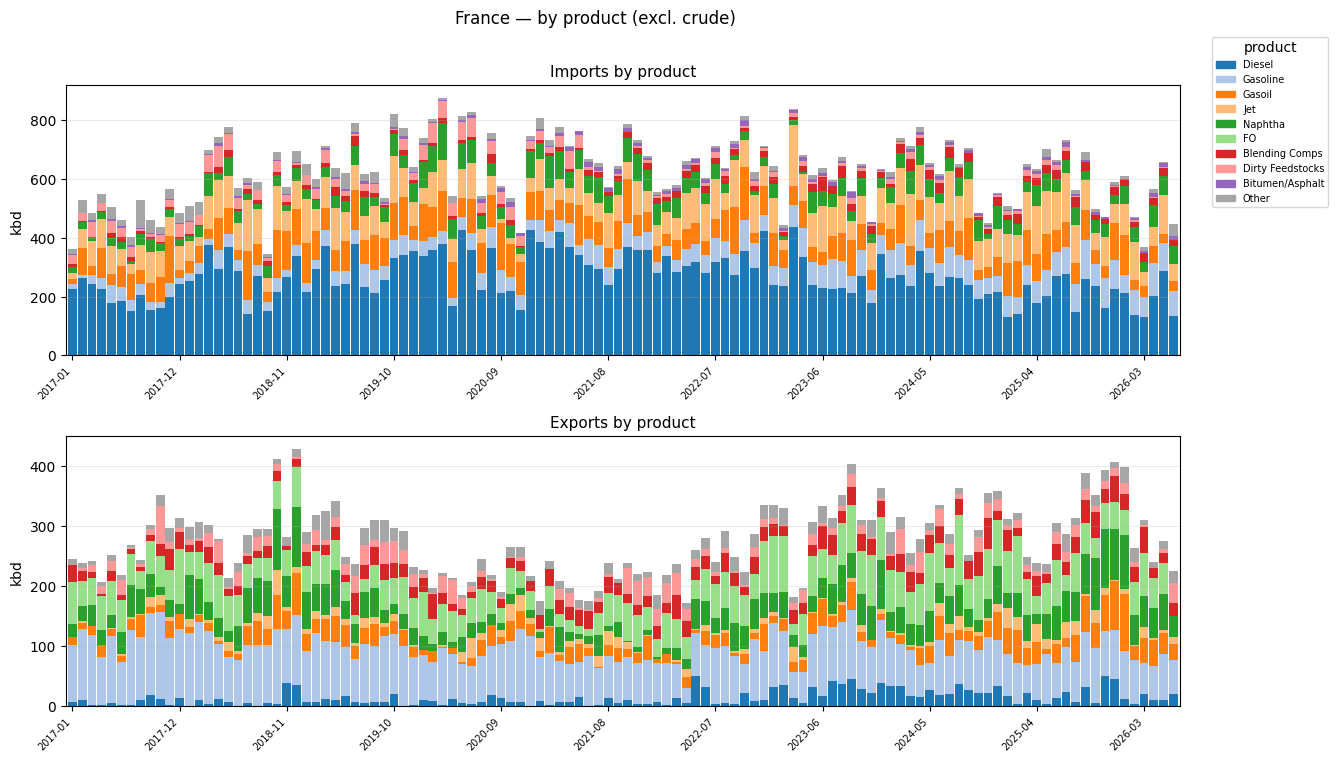

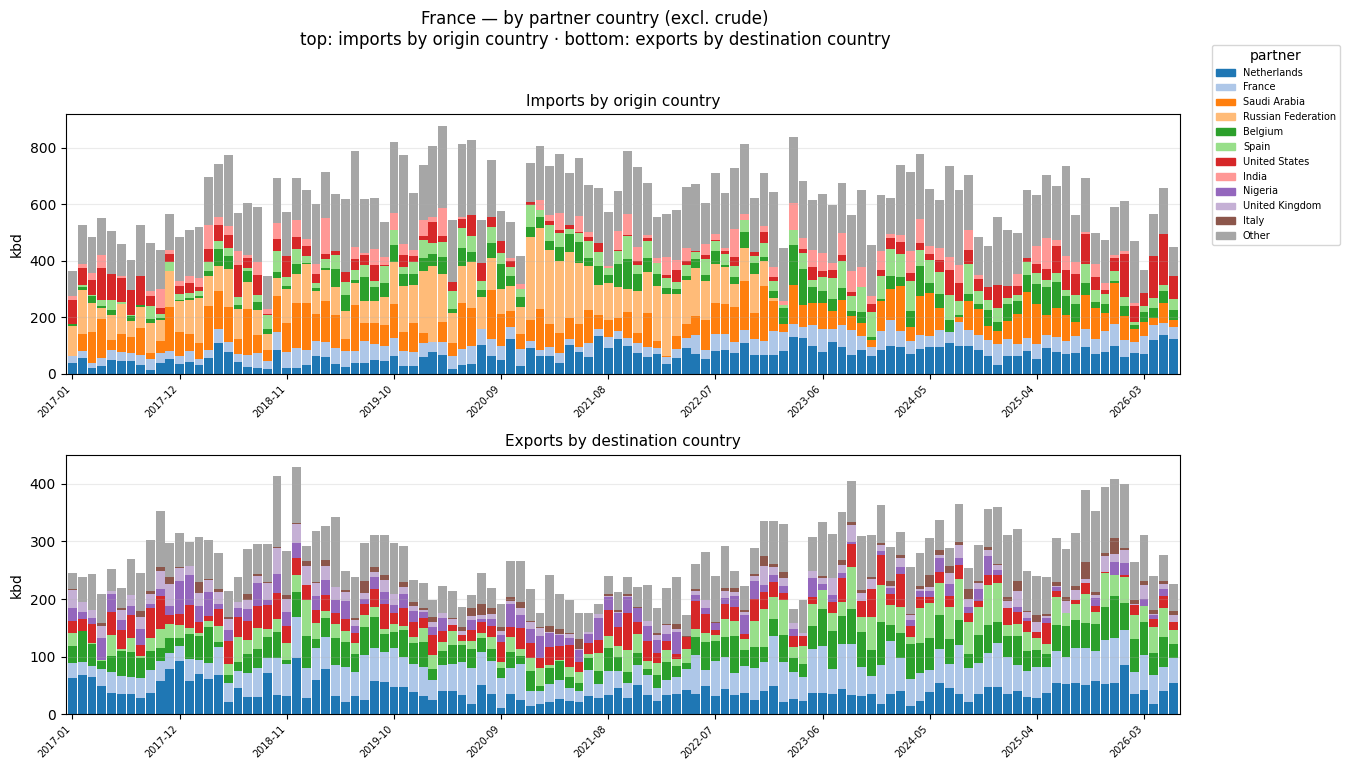

In [30]:
france_products = explore_country_products("France")

### 6c. Portugal — products & terminals

PORTUGAL — PRODUCT INSIGHTS (excl. crude)
Top products (lifetime mb)


,product,family,product_group,trades,volume_mb,pct_of_imports
0,Gasoil,Middle Distillates,Gasoil/Diesel,1972,104.54,27.8
1,Dirty Feedstocks,DPP,Fuel Oils,511,79.53,21.1
2,Gasoline,Light Ends,Gasoline/Naphtha,1399,59.56,15.8
3,Jet,Middle Distillates,Kero/Jet,658,42.77,11.4
4,FO,DPP,Fuel Oils,1144,32.26,8.6
5,Diesel,Middle Distillates,Gasoil/Diesel,182,22.43,6.0
6,Naphtha,Light Ends,Gasoline/Naphtha,305,18.35,4.9
7,Blending Comps,Light Ends,Blendings,213,6.82,1.8
8,Bitumen/Asphalt,DPP,Resids,417,5.93,1.6
9,SRFO,DPP,Fuel Oils,18,2.77,0.7


Most important terminal by product (regional concentration)


,product,top_terminal,terminal_mb,pct_of_product,product_mb,terminal_trades
0,Gasoil,Matosinhos Refinery,48.93,46.8,104.54,850
1,Dirty Feedstocks,Sines Products,74.04,93.1,79.53,442
2,Gasoline,Matosinhos Refinery,27.78,46.6,59.56,699
3,Jet,Sines Products,19.47,45.5,42.77,96
4,FO,ETC Lisbon,12.09,37.5,32.26,607
5,Diesel,Sines Products,7.99,35.6,22.43,21
6,Naphtha,Sines Products,7.54,41.1,18.35,70
7,Blending Comps,Matosinhos Refinery,3.35,49.2,6.82,96
8,Bitumen/Asphalt,Matosinhos Refinery,2.91,49.1,5.93,222
9,SRFO,Sines Products,2.43,87.4,2.77,16


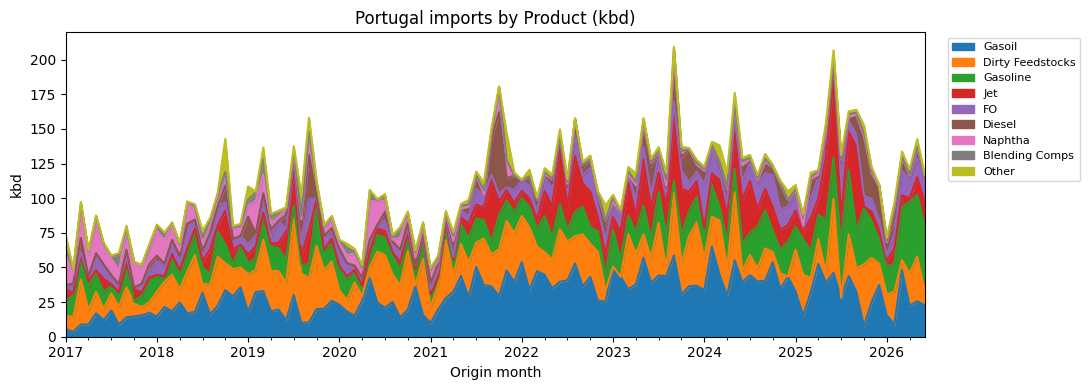

Portugal — product seasonality (kbd)


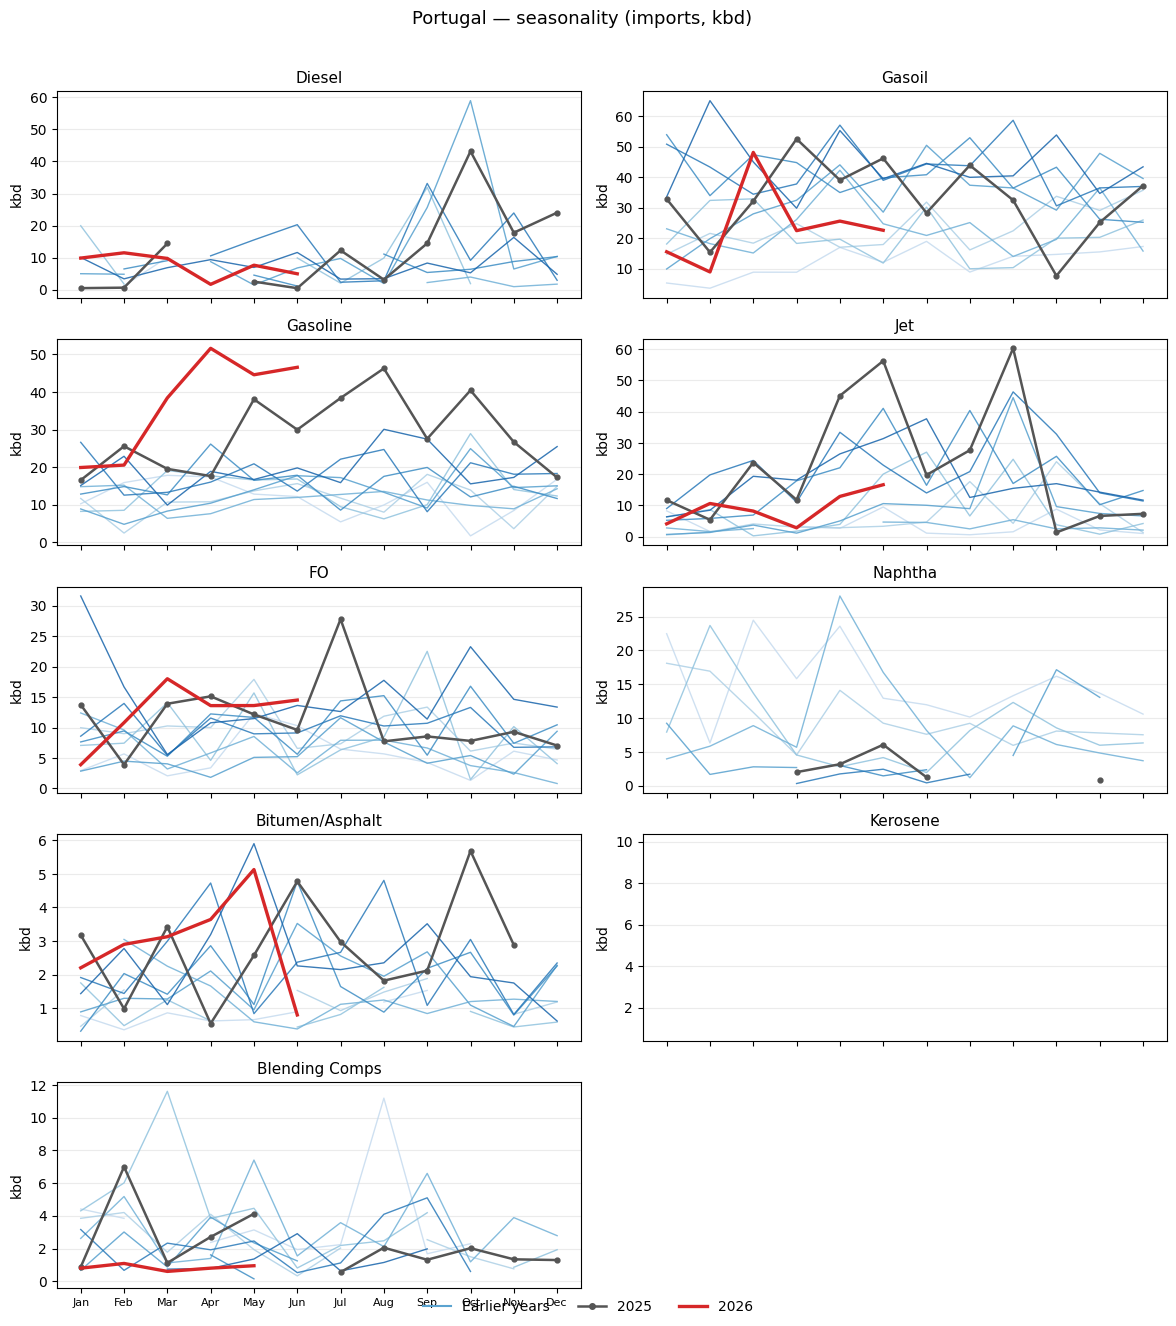

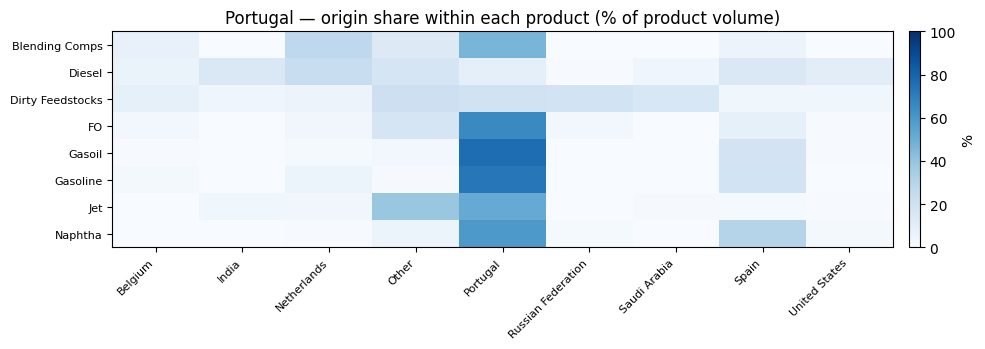

Portugal — import/export stacked bars (monthly kbd)


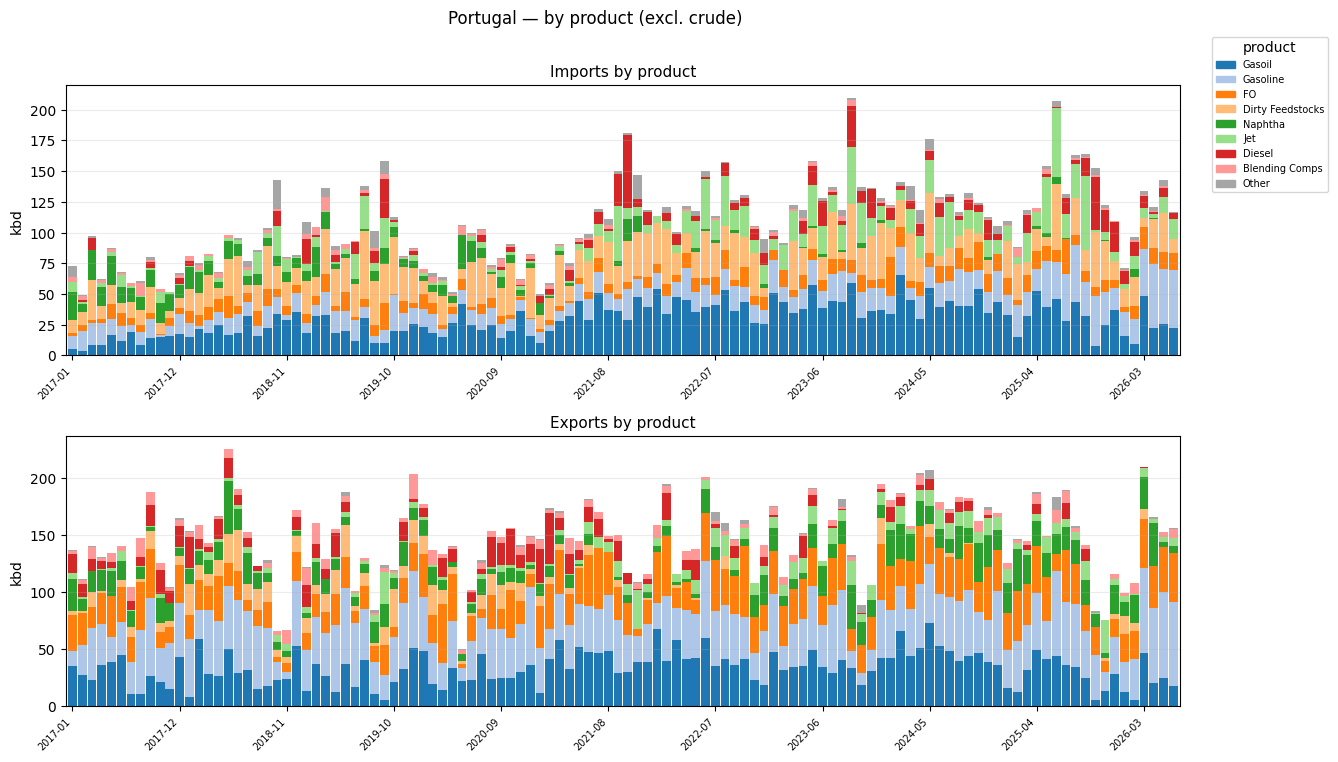

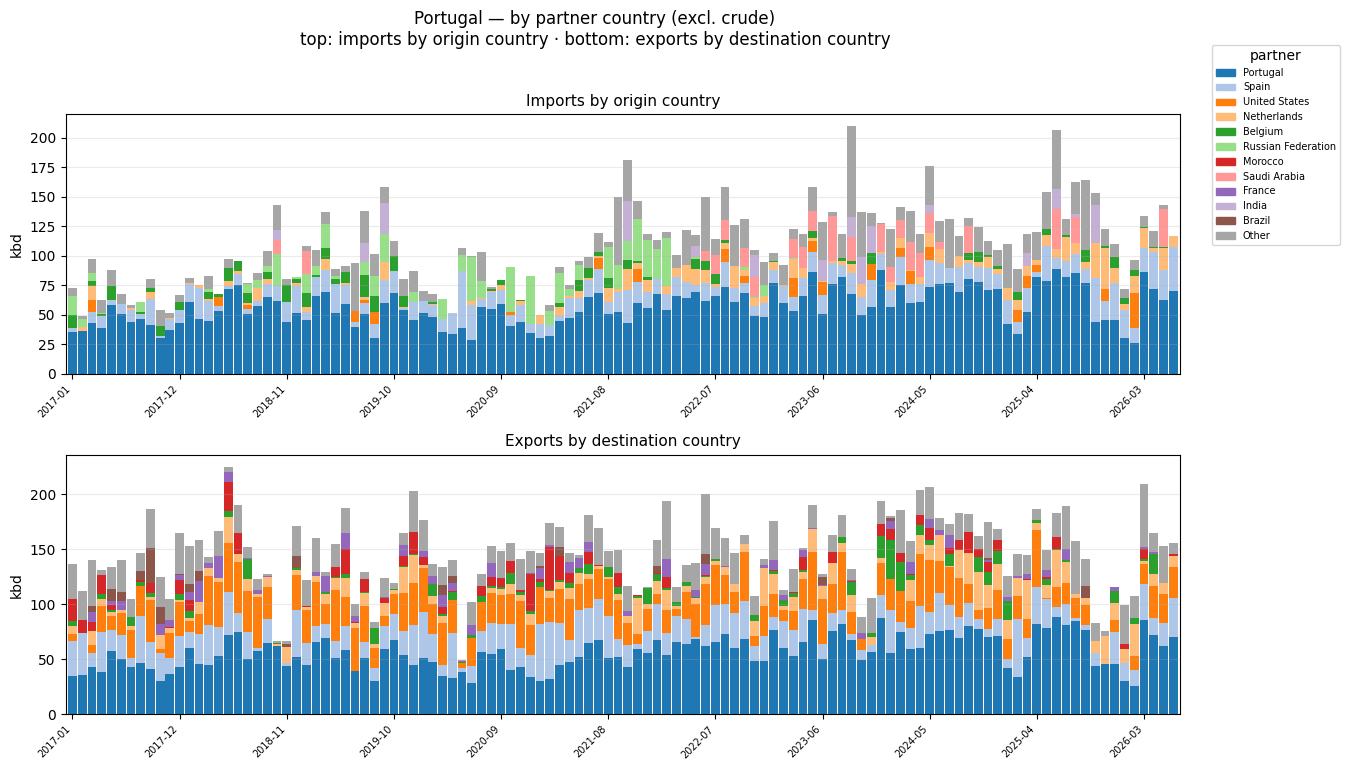

In [31]:
portugal_products = explore_country_products("Portugal")

## 7. Flow Sankeys (terminal / partner / product)

Three-stage Sankey of import/export topology.

- **Imports:** origin country → product → destination terminal
- **Exports:** origin terminal → product → destination country

**Modes** (`SANKEY_MODE` in setup):
- `month` — single month (`SANKEY_MONTH`), values in **kbd**
- `cumulative` — full window `[SANKEY_START, SANKEY_END]`, values in **avg kbd** over the window (total **mb** in the title)

Set `SANKEY_ANNUAL_SNAPSHOTS = True` to also draw one import Sankey per year when mode is cumulative.
Toggle crude with `INCLUDE_CRUDE`. Re-run setup + this section after changing flags.

§7d adds time-series views of the same topology (stacked area, heatmap, concentration).


In [32]:
def _bucket_other(df: pd.DataFrame, col: str, value: str, n: int) -> pd.DataFrame:
    keep = set(df.groupby(col)[value].sum().nlargest(n).index)
    out = df.copy()
    out[col] = out[col].where(out[col].isin(keep), "Other")
    return out


def _days_in_month_range(start: str, end: str) -> int:
    """Inclusive day count between YYYY-MM start/end."""
    idx = pd.period_range(start, end, freq="M")
    return int(sum(days_in_yyyymm(str(p)) for p in idx))


def sankey_flows(
    country: str,
    *,
    direction: str = "import",
    mode: str | None = None,
    month: str | None = None,
    start: str | None = None,
    end: str | None = None,
    include_crude: bool | None = None,
    top_n: int | None = None,
) -> tuple[pd.DataFrame, dict]:
    """
    Long links for a 3-stage Sankey.

    Returns (links_df, meta) where meta has unit, window label, total_mb, etc.
    direction='import'  -> origin_country -> product -> terminal
    direction='export'  -> terminal -> product -> dest_country
    """
    mode = mode or SANKEY_MODE
    top_n = top_n or SANKEY_TOP_N
    crude = crude_sql_filter(include_crude)

    if direction == "import":
        select = f"""
          COALESCE("Country (origin)", '(unknown)') AS stage1,
          COALESCE(Product, '(blank)') AS stage2,
          COALESCE("Installation Destination", '(unknown terminal)') AS stage3,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        """
        where_geo = '"Country (destination)" = ?'
    elif direction == "export":
        select = f"""
          COALESCE("Installation origin", '(unknown terminal)') AS stage1,
          COALESCE(Product, '(blank)') AS stage2,
          COALESCE("Country (destination)", '(unknown)') AS stage3,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        """
        where_geo = '"Country (origin)" = ?'
    else:
        raise ValueError("direction must be 'import' or 'export'")

    if mode == "month":
        month = month or SANKEY_MONTH
        time_sql = f"AND {MONTH} = ?"
        params = [STATUS, country, month]
        window = month
        days = days_in_yyyymm(month)
        unit = "kbd"
    elif mode == "cumulative":
        start = start or SANKEY_START
        end = end or SANKEY_END
        time_sql = f"AND {MONTH} >= ? AND {MONTH} <= ?"
        params = [STATUS, country, start, end]
        window = f"{start} -> {end}"
        days = _days_in_month_range(start, end)
        unit = "avg kbd"
    else:
        raise ValueError("mode must be 'month' or 'cumulative'")

    df = q(
        f"""
        SELECT {select}
        FROM trades
        WHERE "Trade status" = ?
          AND {where_geo}
          {time_sql}
          {crude}
        GROUP BY 1, 2, 3
        """,
        params,
    )
    meta = {
        "mode": mode,
        "window": window,
        "unit": unit,
        "days": days,
        "total_mb": float(df["volume_kb"].sum() / 1000.0) if len(df) else 0.0,
        "direction": direction,
        "crude": crude_label(include_crude),
    }
    if df.empty:
        return df, meta

    df = df.copy()
    df["volume_flow"] = df["volume_kb"] / days
    df = _bucket_other(df, "stage1", "volume_flow", top_n)
    df = _bucket_other(df, "stage2", "volume_flow", top_n)
    df = _bucket_other(df, "stage3", "volume_flow", top_n)
    links = (
        df.groupby(["stage1", "stage2", "stage3"], as_index=False)["volume_flow"]
        .sum()
        .sort_values("volume_flow", ascending=False)
    )
    return links, meta


def plot_sankey(
    links: pd.DataFrame,
    meta: dict,
    *,
    title: str,
    left_label: str,
    mid_label: str,
    right_label: str,
):
    if links is None or links.empty:
        print(f"No flows for: {title}")
        return None

    left = [f"L|{x}" for x in links["stage1"].unique()]
    mid = [f"M|{x}" for x in links["stage2"].unique()]
    right = [f"R|{x}" for x in links["stage3"].unique()]
    labels_raw = left + mid + right
    display_labels = [x.split("|", 1)[1] for x in labels_raw]
    idx = {name: i for i, name in enumerate(labels_raw)}

    sources, targets, values = [], [], []
    leg1 = links.groupby(["stage1", "stage2"], as_index=False)["volume_flow"].sum()
    for _, r in leg1.iterrows():
        sources.append(idx[f"L|{r.stage1}"])
        targets.append(idx[f"M|{r.stage2}"])
        values.append(float(r.volume_flow))
    leg2 = links.groupby(["stage2", "stage3"], as_index=False)["volume_flow"].sum()
    for _, r in leg2.iterrows():
        sources.append(idx[f"M|{r.stage2}"])
        targets.append(idx[f"R|{r.stage3}"])
        values.append(float(r.volume_flow))

    n_l, n_m, n_r = len(left), len(mid), len(right)
    colors = (
        ["rgba(46,160,67,0.85)"] * n_l
        + ["rgba(88,166,255,0.75)"] * n_m
        + ["rgba(121,192,255,0.85)"] * n_r
    )
    unit = meta["unit"]
    subtitle = (
        f"{left_label} -> {mid_label} -> {right_label} · {meta['window']} · "
        f"{meta['crude']} · {meta['total_mb']:.1f} mb total · values in {unit}"
    )

    fig = go.Figure(
        data=[
            go.Sankey(
                arrangement="snap",
                node=dict(
                    pad=14,
                    thickness=14,
                    label=display_labels,
                    color=colors,
                    line=dict(width=0.3, color="rgba(0,0,0,0.3)"),
                ),
                link=dict(
                    source=sources,
                    target=targets,
                    value=values,
                    color="rgba(80,120,180,0.35)",
                    hovertemplate=(
                        "%{source.label} → %{target.label}<br>"
                        f"%{{value:.1f}} {unit}<extra></extra>"
                    ),
                ),
            )
        ]
    )
    fig.update_layout(
        title_text=f"{title}<br><sup>{subtitle}</sup>",
        font_size=11,
        height=560,
        margin=dict(l=10, r=10, t=80, b=20),
    )
    fig.show()
    return fig


def country_sankeys(
    country: str,
    *,
    mode: str | None = None,
    include_crude: bool | None = None,
    month: str | None = None,
    start: str | None = None,
    end: str | None = None,
    annual_snapshots: bool | None = None,
):
    mode = mode or SANKEY_MODE
    annual_snapshots = SANKEY_ANNUAL_SNAPSHOTS if annual_snapshots is None else annual_snapshots

    imp, meta_i = sankey_flows(
        country,
        direction="import",
        mode=mode,
        month=month,
        start=start,
        end=end,
        include_crude=include_crude,
    )
    plot_sankey(
        imp,
        meta_i,
        title=f"{country} imports — origin → product → terminal",
        left_label="Origin country",
        mid_label="Product",
        right_label="Destination terminal",
    )
    if len(imp):
        display(imp.head(20).rename(columns={"volume_flow": meta_i["unit"]}))

    exp, meta_e = sankey_flows(
        country,
        direction="export",
        mode=mode,
        month=month,
        start=start,
        end=end,
        include_crude=include_crude,
    )
    plot_sankey(
        exp,
        meta_e,
        title=f"{country} exports — terminal → product → destination",
        left_label="Origin terminal",
        mid_label="Product",
        right_label="Destination country",
    )
    if len(exp):
        display(exp.head(20).rename(columns={"volume_flow": meta_e["unit"]}))

    annual = {}
    if annual_snapshots and mode == "cumulative":
        y0 = int((start or SANKEY_START)[:4])
        y1 = int((end or SANKEY_END)[:4])
        print(f"Annual import snapshots {y0}-{y1} ({crude_label(include_crude)})")
        for y in range(y0, y1 + 1):
            y_end = f"{y}-12" if y < HIGHLIGHT_YEAR else (end or SANKEY_END)
            links, meta = sankey_flows(
                country,
                direction="import",
                mode="cumulative",
                start=f"{y}-01",
                end=y_end,
                include_crude=include_crude,
            )
            if meta["total_mb"] < 0.5:
                continue
            plot_sankey(
                links,
                meta,
                title=f"{country} imports {y} — origin → product → terminal",
                left_label="Origin country",
                mid_label="Product",
                right_label="Destination terminal",
            )
            annual[y] = links

    return {
        "import": imp,
        "export": exp,
        "meta_import": meta_i,
        "meta_export": meta_e,
        "annual": annual,
    }


def flow_timeseries_imports(
    country: str,
    *,
    include_crude: bool | None = None,
    start: str | None = None,
    end: str | None = None,
    top_n: int = 8,
) -> pd.DataFrame:
    """Monthly import kbd by origin country."""
    crude = crude_sql_filter(include_crude)
    start = start or SANKEY_START
    end = end or SANKEY_END
    df = q(
        f"""
        SELECT
          {MONTH} AS month,
          COALESCE("Country (origin)", '(unknown)') AS origin_country,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          AND {MONTH} >= ? AND {MONTH} <= ?
          {crude}
        GROUP BY 1, 2
        """,
        [STATUS, country, start, end],
    )
    df = add_kbd(df)
    plot_df = top_n_bucket(df, "origin_country", "volume_kbd", top_n)
    return (
        plot_df.groupby(["month", "origin_country"], as_index=False)["volume_kbd"]
        .sum()
        .sort_values(["month", "volume_kbd"], ascending=[True, False])
    )


def plot_flow_timeseries(country: str, include_crude: bool | None = None, top_n: int = 8):
    """Stacked area + share heatmap + concentration lines for import origins."""
    df = flow_timeseries_imports(country, include_crude=include_crude, top_n=top_n)
    label = crude_label(include_crude)
    if df.empty:
        print(f"No flow timeseries for {country}")
        return None

    wide = (
        df.assign(month=lambda x: month_index(x["month"]))
        .pivot(index="month", columns="origin_country", values="volume_kbd")
        .fillna(0)
        .sort_index()
    )
    ordered = wide.sum().sort_values(ascending=False).index.tolist()
    if "Other" in ordered:
        ordered = [c for c in ordered if c != "Other"] + ["Other"]
    wide = wide.reindex(columns=ordered)

    stacked_area_kbd(wide, f"{country} imports by origin (kbd, monthly) — {label}")

    share = wide.div(wide.sum(axis=1).replace(0, np.nan), axis=0) * 100
    heat = share.T
    fig, ax = plt.subplots(figsize=(12, max(3.2, 0.35 * len(heat))))
    im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0, vmax=100)
    xticks = list(range(0, len(heat.columns), max(len(heat.columns) // 12, 1)))
    ax.set_xticks(xticks)
    ax.set_xticklabels([str(heat.columns[i]) for i in xticks], rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index, fontsize=8)
    ax.set_title(f"{country} — origin share of imports (% of month) — {label}")
    fig.colorbar(im, ax=ax, fraction=0.02, pad=0.02, label="%")
    plt.tight_layout()
    plt.show()

    crude = crude_sql_filter(include_crude)
    raw = q(
        f"""
        SELECT
          {MONTH} AS month,
          COALESCE("Country (origin)", '(unknown)') AS origin_country,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          AND {MONTH} >= ? AND {MONTH} <= ?
          {crude}
        GROUP BY 1, 2
        """,
        [STATUS, country, SANKEY_START, SANKEY_END],
    )
    raw = add_kbd(raw)
    rows = []
    for m, g in raw.groupby("month"):
        v = g["volume_kbd"].to_numpy()
        tot = v.sum()
        if tot <= 0:
            continue
        shares = np.sort(v / tot)[::-1]
        hhi = float((shares ** 2).sum())
        rows.append(
            {
                "month": m,
                "top1_share": float(shares[0]),
                "top3_share": float(shares[:3].sum()),
                "hhi": hhi,
                "n_origins": int(len(shares)),
            }
        )
    conc = pd.DataFrame(rows).sort_values("month")
    conc["month"] = month_index(conc["month"])
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(conc["month"].astype(str), conc["top1_share"] * 100, label="Top-1 origin share", lw=1.8)
    ax.plot(conc["month"].astype(str), conc["top3_share"] * 100, label="Top-3 origin share", lw=1.5)
    ax2 = ax.twinx()
    ax2.plot(conc["month"].astype(str), conc["hhi"], color="gray", alpha=0.7, label="HHI", lw=1.2)
    ax.set_ylabel("Share of imports (%)")
    ax2.set_ylabel("HHI (0-1)")
    ax.set_title(f"{country} — import origin concentration — {label}")
    step = max(len(conc) // 10, 1)
    ax.set_xticks(range(0, len(conc), step))
    ax.set_xticklabels(conc["month"].astype(str).iloc[::step], rotation=45, ha="right", fontsize=7)
    lines1, lab1 = ax.get_legend_handles_labels()
    lines2, lab2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, lab1 + lab2, loc="upper left", fontsize=8)
    ax.grid(True, axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    return {"wide_kbd": wide, "share": share, "concentration": conc}


print(
    f"Sankey defaults: mode={SANKEY_MODE}, month={SANKEY_MONTH}, "
    f"window=[{SANKEY_START}, {SANKEY_END}], INCLUDE_CRUDE={INCLUDE_CRUDE}, "
    f"annual={SANKEY_ANNUAL_SNAPSHOTS}, top_n={SANKEY_TOP_N}"
)


Sankey defaults: mode=month, month=2026-06, window=[2016-01, 2026-06], INCLUDE_CRUDE=False, annual=True, top_n=10


### 7a. Spain — flows

In [33]:
#spain_sankey = country_sankeys("Spain")
# Examples:
spain_sankey_cum = country_sankeys("Spain", mode="cumulative")
# spain_sankey_crude = country_sankeys("Spain", include_crude=True)


,stage1,stage2,stage3,avg kbd
547,Spain,Gasoil,Other,29.270039
536,Spain,FO,Other,15.772241
558,Spain,Gasoline,Other,12.433119
550,Spain,Gasoil,Tenerife Refinery,11.907907
283,Other,FO,Other,10.531447
327,Other,Naphtha,Tarragona Refinery,9.837917
103,Italy,Diesel,Other,9.483001
132,Italy,Gasoil,Other,9.012138
287,Other,FO,Vopak Algeciras,8.560354
544,Spain,Gasoil,CEPSA Las Palmas,8.519740


,stage1,stage2,stage3,avg kbd
370,Other,Gasoil,Other,16.379178
275,Gibraltar-San Roque Refinery,Gasoil,Spain,12.570755
381,Other,Gasoline,Other,12.437080
641,Torre Arenillas,Gasoil,Spain,10.816211
480,Repsol Cartagena Refinery,Naphtha,Brazil,10.645658
137,BP Castellon Refinery,Gasoil,Spain,9.402107
702,Vopak Terquimsa Barcelona,Gasoline,Other,9.342827
585,Tarragona Refinery,FO,Spain,8.561379
282,Gibraltar-San Roque Refinery,Gasoline,Other,8.438392
359,Other,FO,Other,8.162854


Annual import snapshots 2016-2026 (excl. crude)


### 7b. France — flows

In [34]:
france_sankey = country_sankeys("France")
# Examples:
# france_sankey_cum = country_sankeys("France", mode="cumulative")
# france_sankey_crude = country_sankeys("France", include_crude=True)


,stage1,stage2,stage3,kbd
42,Netherlands,Diesel,Donges Refinery,28.919033
67,Saudi Arabia,Gasoil,La Rochelle,23.798100
33,Italy,Naphtha,La Mede & Fluxys Lavera,21.017167
34,Italy,Naphtha,Total Mardyck,20.364267
35,Libya,Clean Condensate,Fos Sur Mer,17.707900
85,United States,Jet,Le Havre,16.964233
48,Netherlands,Gasoline,Donges Refinery,14.710900
0,Angola,Clean Condensate,Total Mardyck,11.869900
52,Netherlands,Gasoline,La Rochelle,11.452600
43,Netherlands,Diesel,EPG Ambes,10.612367


,stage1,stage2,stage3,kbd
48,North Atlantic Port Jerome Refinery,Naphtha,Netherlands,11.583000
45,North Atlantic Port Jerome Refinery,Gasoline,Belgium,11.526267
24,Fos Sur Mer,Naphtha,United States,11.514100
49,North Atlantic Port Jerome Refinery,Slurry,Netherlands,11.066233
25,La Mede & Fluxys Lavera,Dirty Feedstocks,Spain,10.645267
27,La Mede & Fluxys Lavera,Gasoil,Algeria,9.396333
34,La Mede & Fluxys Lavera,Naphtha,Libya,9.240333
32,La Mede & Fluxys Lavera,Gasoline,Spain,8.853300
35,Le Havre,Diesel,France,8.773233
46,North Atlantic Port Jerome Refinery,Gasoline,Netherlands,8.203500


### 7c. Portugal — flows

In [35]:
portugal_sankey = country_sankeys("Portugal")
# Examples:
# portugal_sankey_cum = country_sankeys("Portugal", mode="cumulative")
# portugal_sankey_crude = country_sankeys("Portugal", include_crude=True)


,stage1,stage2,stage3,kbd
13,Portugal,Gasoline,Matosinhos Refinery,13.547100
14,Portugal,Gasoline,Prio Energy Aveiro,12.149767
19,Spain,Dirty Feedstocks,Sines Products,10.855567
26,Spain,Jet,Sines Products,9.525267
9,Portugal,Gasoil,Matosinhos Refinery,7.791133
5,Portugal,FO,ETC Lisbon,6.481800
11,Portugal,Gasoline,CLCM Madeira,5.689533
17,Portugal,Jet,Matosinhos Refinery,5.689300
24,Spain,Gasoil,Matosinhos Refinery,5.318367
25,Spain,Gasoline,Matosinhos Refinery,5.318167


,stage1,stage2,stage3,kbd
11,Sines Products,Gasoline,Portugal,33.442300
7,Sines Products,FO,Spain,33.272867
12,Sines Products,Gasoline,United States,27.649300
9,Sines Products,Gasoil,Portugal,17.229333
6,Sines Products,FO,Portugal,9.555400
10,Sines Products,Gasoline,Nigeria,7.565967
14,Sines Products,Jet,Portugal,7.111633
15,Sines Products,Naphtha,Netherlands,5.344833
5,Sines Products,Blending Comps,Netherlands,5.344567
3,ETC Lisbon,Gasoline,Portugal,3.037333


### 7d. Flow time series (origins over time)

Sankeys are snapshots. For evolution:
1. monthly stacked area (top origins, kbd)
2. origin × month share heatmap
3. concentration (top-1 / top-3 share + HHI)


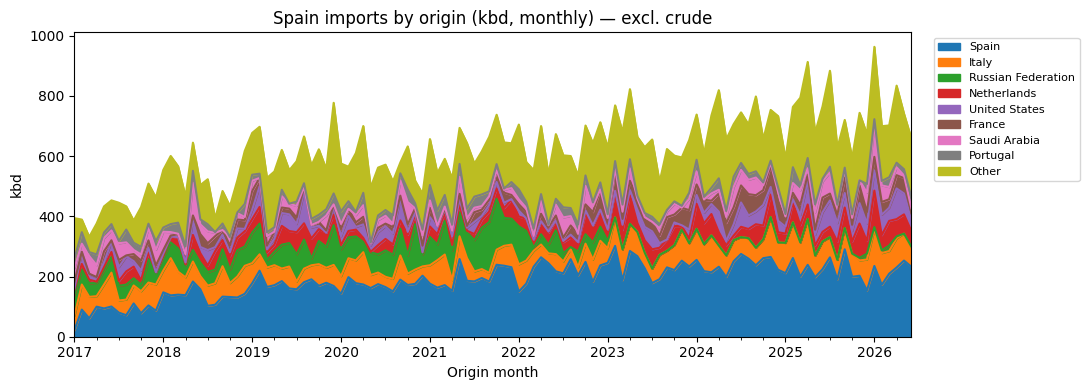

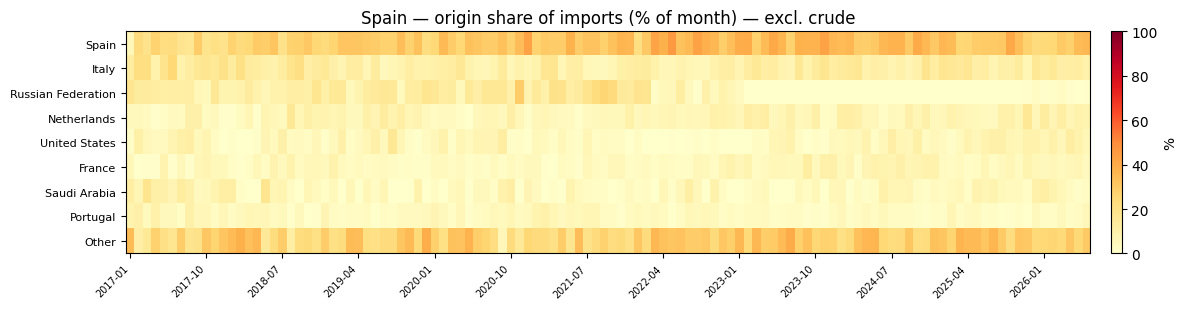

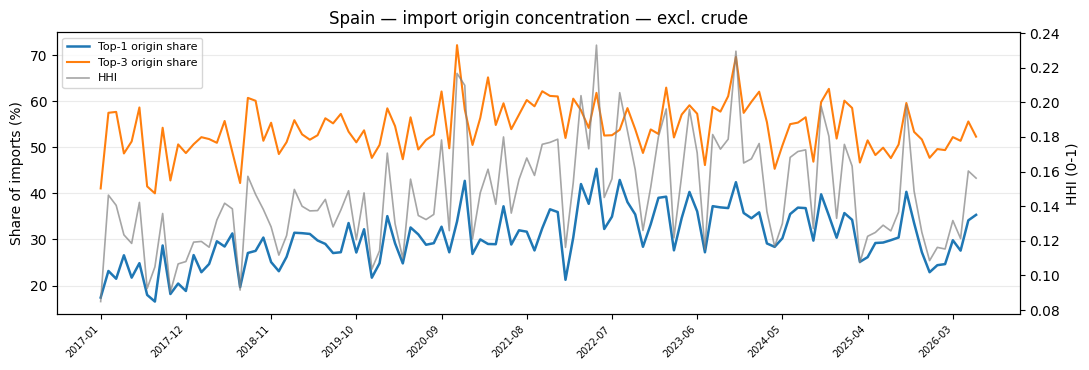

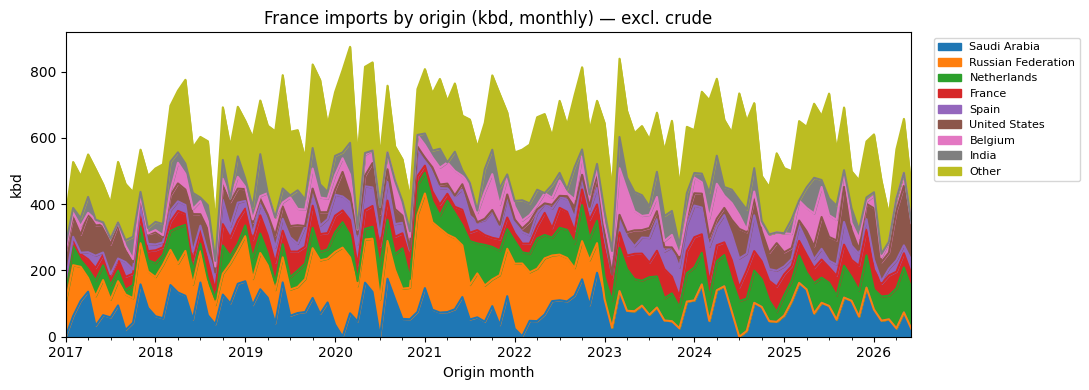

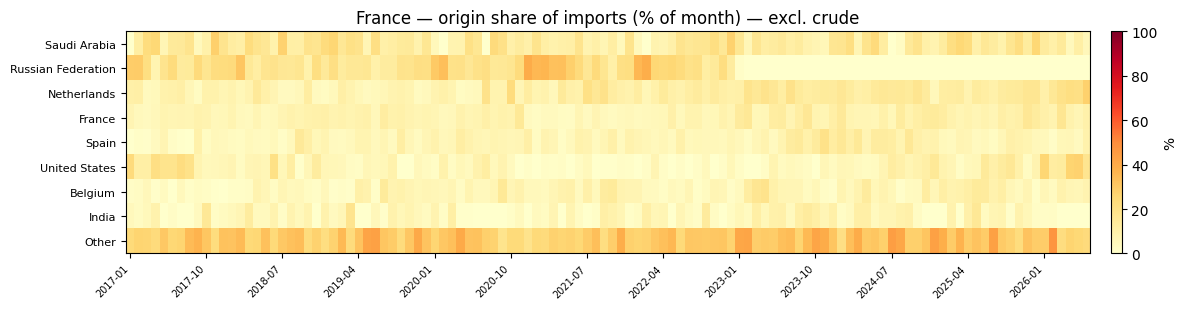

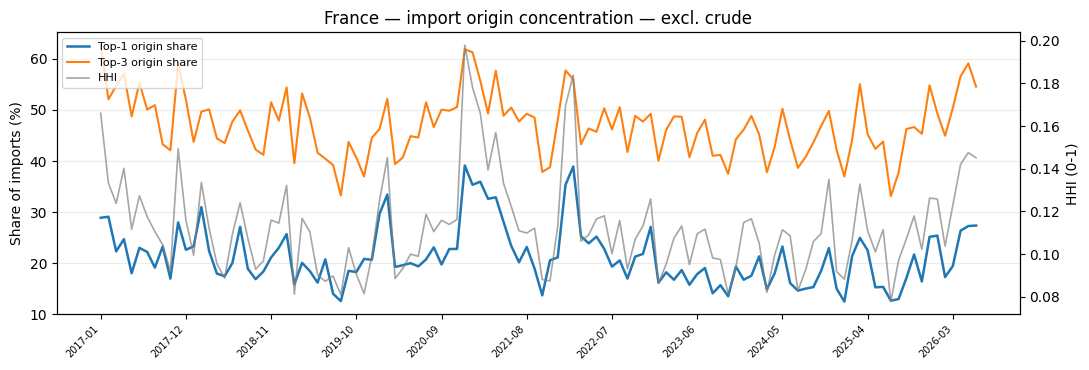

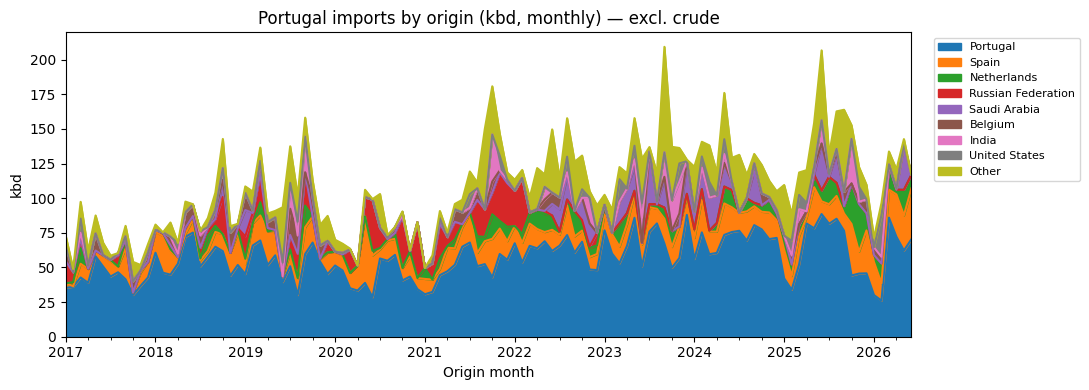

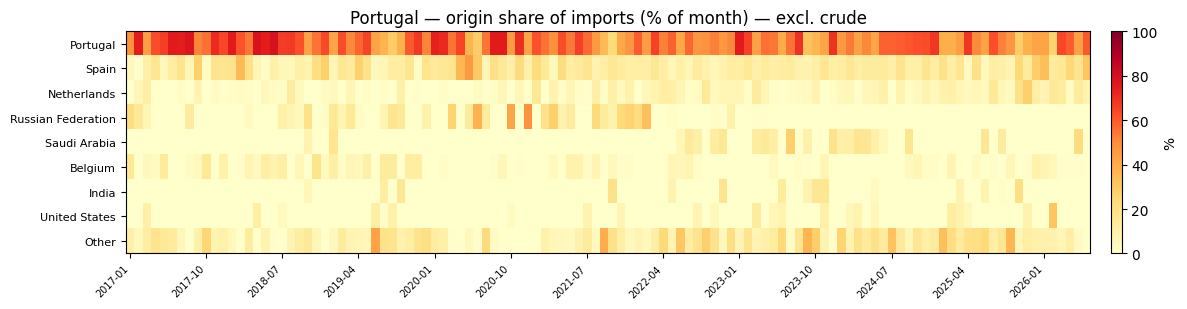

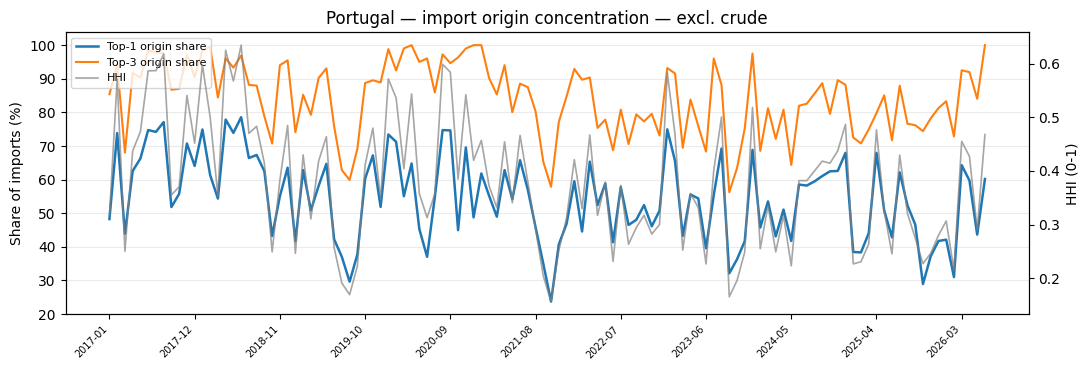

In [36]:
flow_ts = {c: plot_flow_timeseries(c) for c in COUNTRIES}


## 8. Crude into refineries vs product imports (heuristic, monthly kbd)

Note: this section always includes crude (it is the object of study). Product/Sankey sections above respect `INCLUDE_CRUDE`.

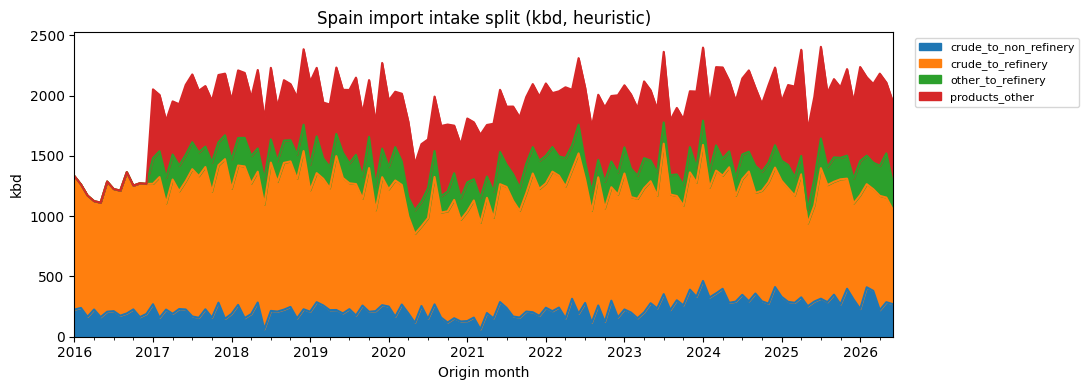

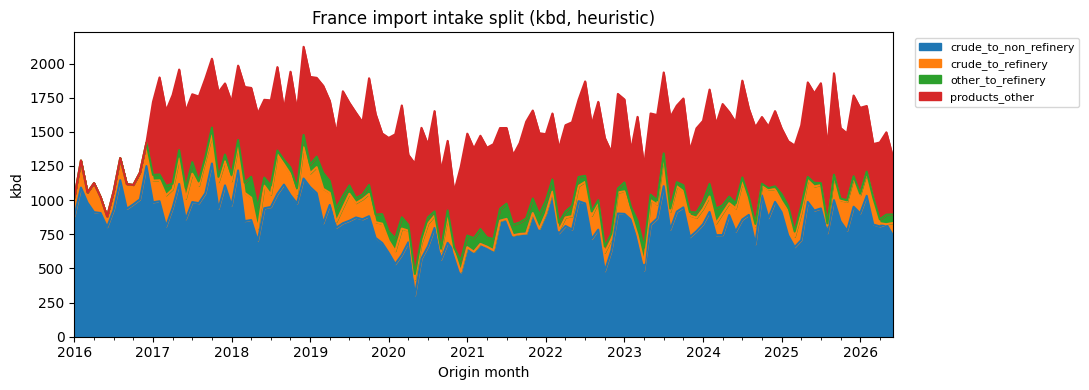

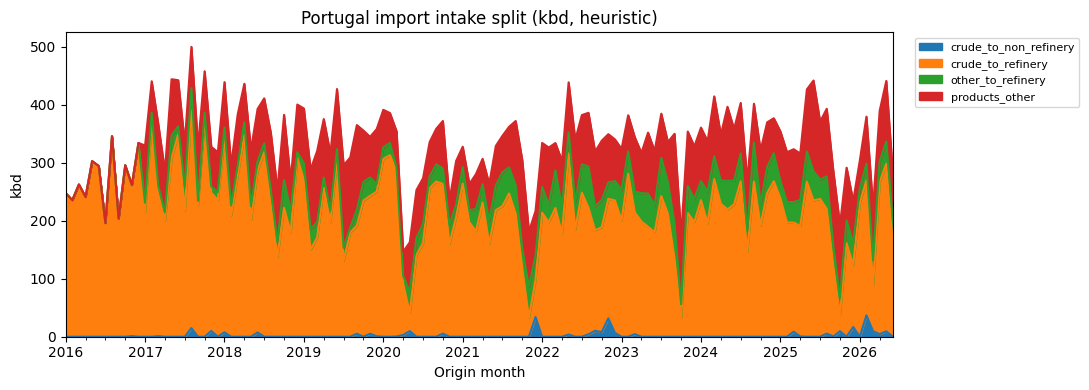

In [37]:
def intake_split_monthly(country: str) -> pd.DataFrame:
    df = q(
        f"""
        SELECT
          {MONTH} AS month,
          CASE
            WHEN "Installation Destination" ILIKE '%refinery%'
              AND (Family = 'Dirty' OR Product = 'Crude' OR "Group" = 'Crude/Co')
              THEN 'crude_to_refinery'
            WHEN "Installation Destination" ILIKE '%refinery%'
              THEN 'other_to_refinery'
            WHEN Family = 'Dirty' OR Product = 'Crude' OR "Group" = 'Crude/Co'
              THEN 'crude_to_non_refinery'
            ELSE 'products_other'
          END AS bucket,
          ROUND(SUM({VOL}) / 1000.0, 3) AS volume_kb
        FROM trades
        WHERE "Trade status" = ?
          AND "Country (destination)" = ?
          AND "Date (origin)" IS NOT NULL
        GROUP BY 1, 2
        HAVING month >= '2016-01' AND month <= ?
        """,
        [STATUS, country, SEASONALITY_END],
    )
    return add_kbd(df)


def plot_intake_monthly(country: str):
    df = intake_split_monthly(country)
    wide = (
        df.assign(month=lambda x: month_index(x["month"]))
        .pivot(index="month", columns="bucket", values="volume_kbd")
        .fillna(0)
        .sort_index()
    )
    stacked_area_kbd(wide, f"{country} import intake split (kbd, heuristic)")
    return wide


intake_tables = {c: plot_intake_monthly(c) for c in COUNTRIES}

## Ops notes

- **kbd** = monthly thousand barrels / days in month
- Lifetime aggregates stay in **mb**
- `INCLUDE_CRUDE`, `SANKEY_MODE` (`month`|`cumulative`), `SANKEY_START`/`END`, `SANKEY_ANNUAL_SNAPSHOTS`
- Cumulative Sankey values = **average kbd** over the window (widths comparable to monthly)
- Flow evolution: §7d stacked area + heatmap + concentration
- Example: `country_sankeys("Spain", mode="cumulative")`
- Refresh: `python refresh_trades.py --days 180`
